In [1]:
# ============================================================
# Block 0 (Updated): Imports, Config, Reproducibility
# ============================================================
import os, shutil, random, math, json, time, hashlib, warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import cv2
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
import timm

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display as ipy_display, Image as IPyImage

from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score, balanced_accuracy_score)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity  as ssim

warnings.filterwarnings("ignore", category=UserWarning)

# ── Config ────────────────────────────────────────────────────
SEED       = 42
WORK_DIR   = "/kaggle/working"
PRETRAINED = True            # False only for quick offline smoke tests
IMG_EXTS   = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

seed_everything()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False

device      = torch.device("cuda" if torch.cuda.is_available() else "cpu")
classes     = ["Healthy Leaves", "Powdery Mildew", "Downey Mildew", "Bacterial Rot"]
num_classes = len(classes)
print("Device:", device, "| Classes:", classes)

Device: cuda | Classes: ['Healthy Leaves', 'Powdery Mildew', 'Downey Mildew', 'Bacterial Rot']


In [2]:
# ============================================================
# Block 1: Paths & Dataset Detection
# ============================================================

DATA_DIR = (
    "/kaggle/input/datasets/sumiayasharif/grapedisease"
    "/Niphad Grape Leaf Disease Dataset (NGLD)"
    "/Niphad Grape Leaf Disease Dataset (NGLD)"
)

image_exts = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

print("Checking DATA_DIR:", DATA_DIR)
print("Exists:", os.path.isdir(DATA_DIR))
print()

total_images = 0
for cls in classes:
    cls_path = os.path.join(DATA_DIR, cls)
    exists   = os.path.isdir(cls_path)
    if exists:
        files = [f for f in os.listdir(cls_path)
                 if f.lower().endswith(image_exts)]
        n = len(files)
        total_images += n
        print(f"  {cls:15s}: {n:5d} images   path OK")
    else:
        # Try case-insensitive fallback
        parent_items = os.listdir(DATA_DIR) if os.path.isdir(DATA_DIR) else []
        match = next((x for x in parent_items if x.lower() == cls.lower()), None)
        if match:
            cls_path = os.path.join(DATA_DIR, match)
            files    = [f for f in os.listdir(cls_path)
                        if f.lower().endswith(image_exts)]
            n        = len(files)
            total_images += n
            print(f"  {cls:15s}: {n:5d} images   (found as '{match}')")
        else:
            print(f"  {cls:15s}: NOT FOUND — check folder name")

print()
print("Total images found:", total_images)

Checking DATA_DIR: /kaggle/input/datasets/sumiayasharif/grapedisease/Niphad Grape Leaf Disease Dataset (NGLD)/Niphad Grape Leaf Disease Dataset (NGLD)
Exists: True

  Healthy Leaves :  1254 images   path OK
  Powdery Mildew :   406 images   path OK
  Downey Mildew  :   966 images   path OK
  Bacterial Rot  :   100 images   path OK

Total images found: 2726


In [3]:
# ============================================================
# Block 2: Preprocessing — CLAHE + Gaussian Smoothing
# Novel step: CLAHE in LAB color space preserves hue while
# boosting lesion contrast (not done in prior NGLD works).
# ============================================================

PREPROC_DIR = "/kaggle/working/grape_preprocessed"
os.makedirs(PREPROC_DIR, exist_ok=True)

TARGET_SIZE = (224, 224)

def preprocess_image(img_path: str):
    """
    Returns (original_rgb, processed_rgb) both as uint8 numpy arrays.
    Processing:
      1. Resize to TARGET_SIZE
      2. Convert to LAB color space
      3. CLAHE on L-channel (preserves color, boosts contrast)
      4. Gaussian blur on L-channel (suppress noise)
      5. Merge back to RGB
    """
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        return None, None

    img_bgr = cv2.resize(img_bgr, TARGET_SIZE)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # LAB CLAHE
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b_ch = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_clahe = clahe.apply(l)
    l_smooth = cv2.GaussianBlur(l_clahe, (3, 3), 0)

    lab_proc = cv2.merge([l_smooth, a, b_ch])
    proc_bgr = cv2.cvtColor(lab_proc, cv2.COLOR_LAB2BGR)
    proc_rgb = cv2.cvtColor(proc_bgr, cv2.COLOR_BGR2RGB)

    return img_rgb, proc_rgb


psnr_vals, ssim_vals = [], []
counter = 0

for cls in classes:
    in_dir  = os.path.join(DATA_DIR, cls)
    out_dir = os.path.join(PREPROC_DIR, cls)
    os.makedirs(out_dir, exist_ok=True)

    files = [f for f in os.listdir(in_dir)
             if f.lower().endswith(image_exts)]
    print(f"Preprocessing {cls}: {len(files)} images …")

    for fname in files:
        orig, proc = preprocess_image(os.path.join(in_dir, fname))
        if orig is None:
            continue

        out_name = Path(fname).stem + ".png"
        Image.fromarray(proc).save(os.path.join(out_dir, out_name))

        # Collect quality metrics on first 200 images
        if counter < 200:
            g1 = cv2.cvtColor(orig, cv2.COLOR_RGB2GRAY)
            g2 = cv2.cvtColor(proc, cv2.COLOR_RGB2GRAY)
            psnr_vals.append(psnr(g1, g2, data_range=255))
            ssim_vals.append(ssim(g1, g2, data_range=255))
            counter += 1

print()
print(f"Preprocessing done.  Avg PSNR: {np.mean(psnr_vals):.2f} dB"
      f"   Avg SSIM: {np.mean(ssim_vals):.4f}")

Preprocessing Healthy Leaves: 1254 images …
Preprocessing Powdery Mildew: 406 images …
Preprocessing Downey Mildew: 966 images …
Preprocessing Bacterial Rot: 100 images …

Preprocessing done.  Avg PSNR: 24.24 dB   Avg SSIM: 0.8985


=== Sanity Check ===
  Healthy Leaves   orig=1254  proc=1254
  Powdery Mildew   orig= 406  proc= 406
  Downey Mildew    orig= 966  proc= 966
  Bacterial Rot    orig= 100  proc= 100

  Loaded  Healthy Leaves/Healthy Leaves_1.jpg  orig=(224, 224, 3)  proc=(224, 224, 3)  orig_range=[0,240]  proc_range=[0,252]
  Loaded  Healthy Leaves/Healthy Leaves_10.jpg  orig=(224, 224, 3)  proc=(224, 224, 3)  orig_range=[0,224]  proc_range=[0,253]
  Loaded  Powdery Mildew/Powdery Mildew_1.jpg  orig=(224, 224, 3)  proc=(224, 224, 3)  orig_range=[0,255]  proc_range=[0,255]
  Loaded  Powdery Mildew/Powdery Mildew_10.jpg  orig=(224, 224, 3)  proc=(224, 224, 3)  orig_range=[0,223]  proc_range=[0,242]
  Loaded  Downey Mildew/Downey Mildew_1.JPG  orig=(224, 224, 3)  proc=(224, 224, 3)  orig_range=[3,207]  proc_range=[0,237]
  Loaded  Downey Mildew/Downey Mildew_10.jpg  orig=(224, 224, 3)  proc=(224, 224, 3)  orig_range=[0,238]  proc_range=[0,250]
  Loaded  Bacterial Rot/Bacterial Leaf Spot_1.png  orig=(224, 2

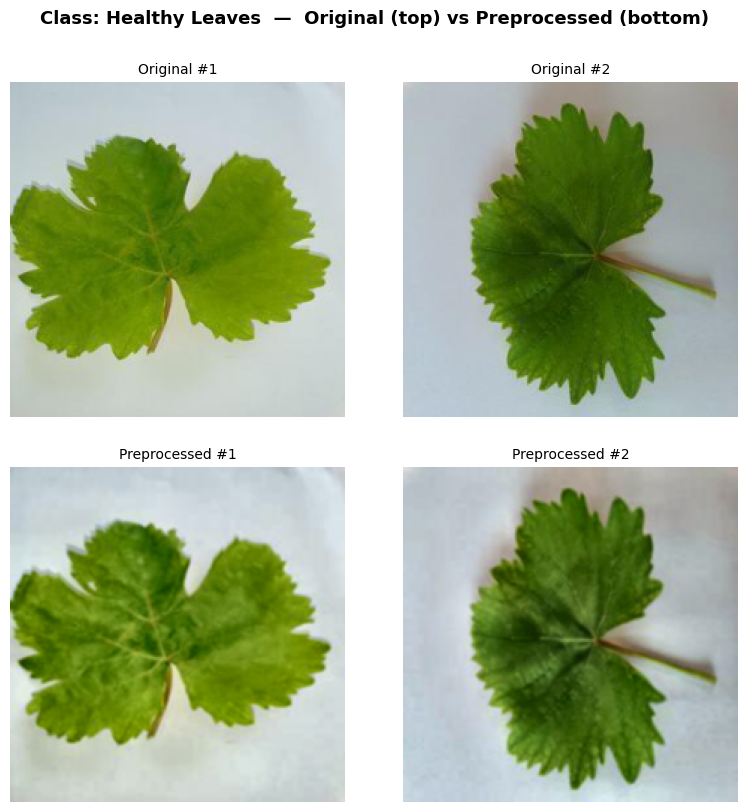

Saved: /kaggle/working/preproc_Powdery Mildew.png


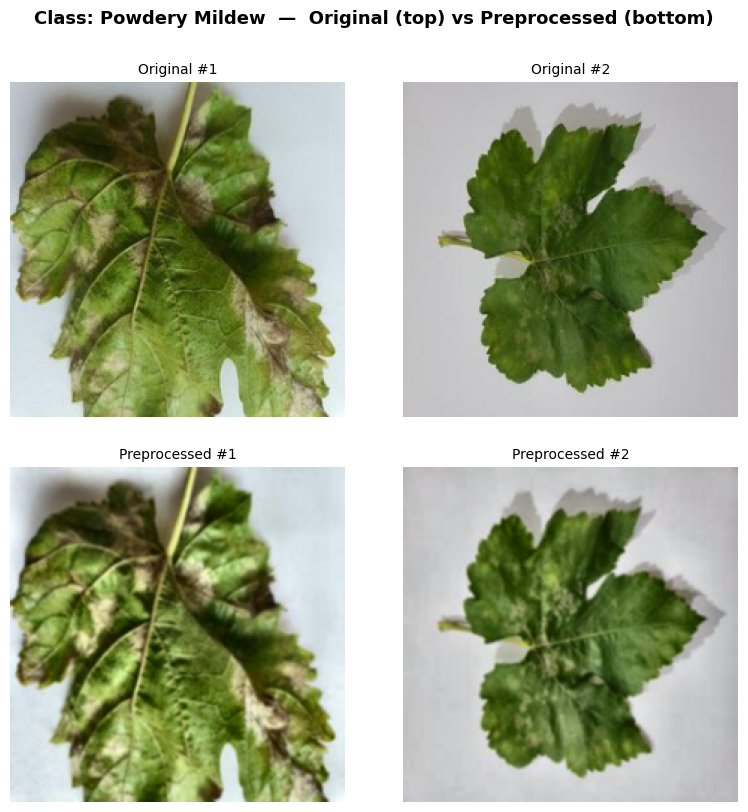

Saved: /kaggle/working/preproc_Downey Mildew.png


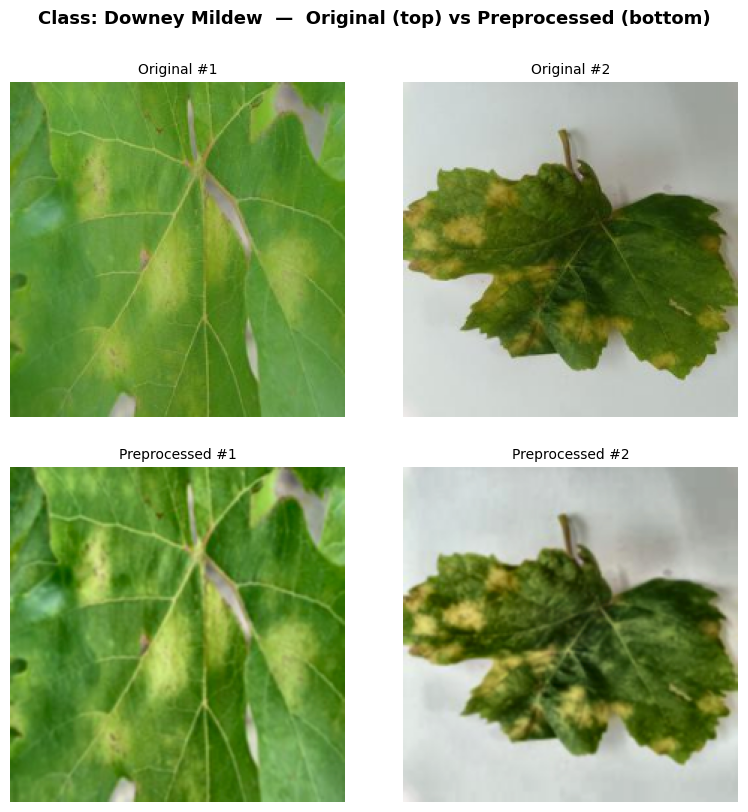

Saved: /kaggle/working/preproc_Bacterial Rot.png


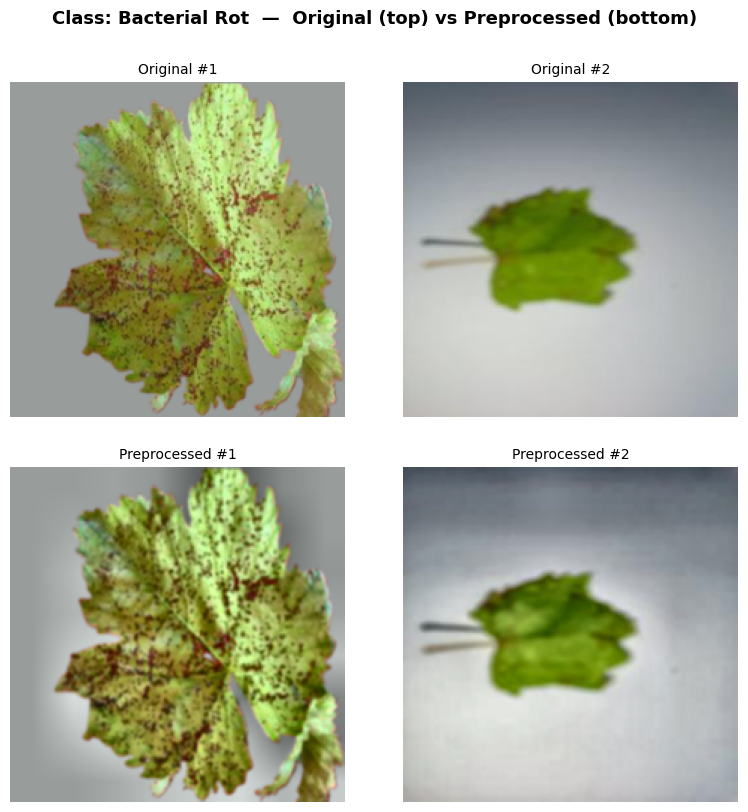

In [4]:
# ============================================================
# Block 2b (Fixed v2): Visualize Preprocessed Images
# ============================================================

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import os
import cv2
from PIL import Image
from IPython.display import display as ipy_display

image_exts = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

# ── Step 1: Quick sanity print — confirm images exist ─────────
print("=== Sanity Check ===")
for cls in classes:
    orig_dir = os.path.join(DATA_DIR, cls)
    proc_dir = os.path.join(PREPROC_DIR, cls)

    orig_files = [f for f in os.listdir(orig_dir)
                  if f.lower().endswith(image_exts)]
    proc_files = [f for f in os.listdir(proc_dir)
                  if f.lower().endswith((".png",))]

    print(f"  {cls:15s}  orig={len(orig_files):4d}  proc={len(proc_files):4d}")

print()

# ── Step 2: Load images into memory first, then plot ──────────
n_per_class = 2      # keep it small so you can actually see them
collected   = {}     # cls -> [(orig_rgb, proc_rgb), ...]

for cls in classes:
    orig_dir  = os.path.join(DATA_DIR,    cls)
    proc_dir  = os.path.join(PREPROC_DIR, cls)

    orig_files = sorted([f for f in os.listdir(orig_dir)
                         if f.lower().endswith(image_exts)])[:n_per_class]

    pairs = []
    for fname in orig_files:
        # Original
        bgr = cv2.imread(os.path.join(orig_dir, fname))
        if bgr is None:
            print(f"  WARNING: could not read {fname}")
            continue
        orig_rgb = cv2.cvtColor(cv2.resize(bgr, (224, 224)),
                                cv2.COLOR_BGR2RGB)

        # Preprocessed
        proc_name = os.path.splitext(fname)[0] + ".png"
        proc_path = os.path.join(proc_dir, proc_name)
        if not os.path.exists(proc_path):
            print(f"  WARNING: preprocessed not found: {proc_path}")
            continue
        proc_rgb = np.array(Image.open(proc_path).convert("RGB"))

        pairs.append((orig_rgb, proc_rgb))
        print(f"  Loaded  {cls}/{fname}  orig={orig_rgb.shape}  "
              f"proc={proc_rgb.shape}  "
              f"orig_range=[{orig_rgb.min()},{orig_rgb.max()}]  "
              f"proc_range=[{proc_rgb.min()},{proc_rgb.max()}]")

    collected[cls] = pairs

print(f"\nLoaded {sum(len(v) for v in collected.values())} image pairs total.")
print()

# ── Step 3: One figure per class — avoids layout conflicts ────
for cls, pairs in collected.items():
    if not pairs:
        print(f"No pairs for {cls}, skipping.")
        continue

    n     = len(pairs)
    fig, axes = plt.subplots(2, n, figsize=(n * 4, 8),
                              facecolor="white")
    if n == 1:
        axes = axes.reshape(2, 1)

    fig.suptitle(f"Class: {cls}  —  Original (top) vs Preprocessed (bottom)",
                 fontsize=13, fontweight="bold", y=1.01)

    for i, (orig, proc) in enumerate(pairs):
        axes[0, i].imshow(orig)
        axes[0, i].set_title(f"Original #{i+1}", fontsize=10)
        axes[0, i].axis("off")

        axes[1, i].imshow(proc)
        axes[1, i].set_title(f"Preprocessed #{i+1}", fontsize=10)
        axes[1, i].axis("off")

    plt.subplots_adjust(wspace=0.05, hspace=0.15,
                        left=0.02, right=0.98,
                        top=0.92, bottom=0.02)

    save_path = f"/kaggle/working/preproc_{cls}.png"
    plt.savefig(save_path, dpi=120, bbox_inches="tight",
                facecolor="white")
    print(f"Saved: {save_path}")

    # Force display in notebook
    ipy_display(fig)
    plt.close(fig)


Healthy Leaves:
  L-channel before → mean=175.4  std=41.5  min=78  max=229
  L-channel after  → mean=178.2  std=45.9  min=57  max=240
  Saved: /kaggle/working/clahe_Healthy Leaves.png


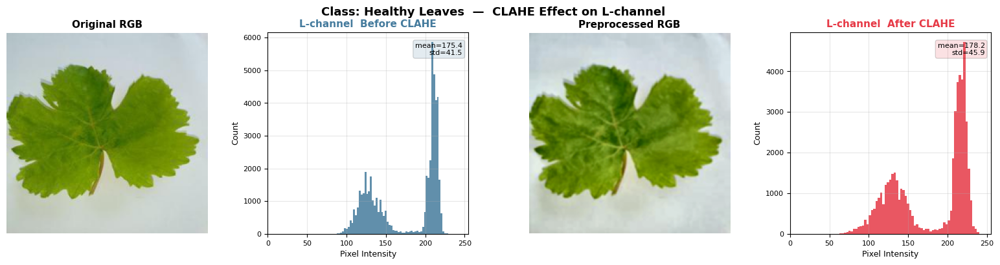


Powdery Mildew:
  L-channel before → mean=143.7  std=58.0  min=15  max=253
  L-channel after  → mean=151.5  std=62.9  min=11  max=255
  Saved: /kaggle/working/clahe_Powdery Mildew.png


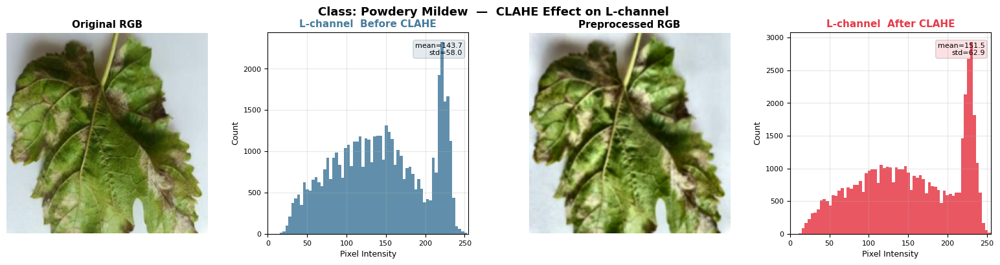


Downey Mildew:
  L-channel before → mean=143.5  std=16.4  min=97  max=202
  L-channel after  → mean=140.1  std=28.3  min=63  max=233
  Saved: /kaggle/working/clahe_Downey Mildew.png


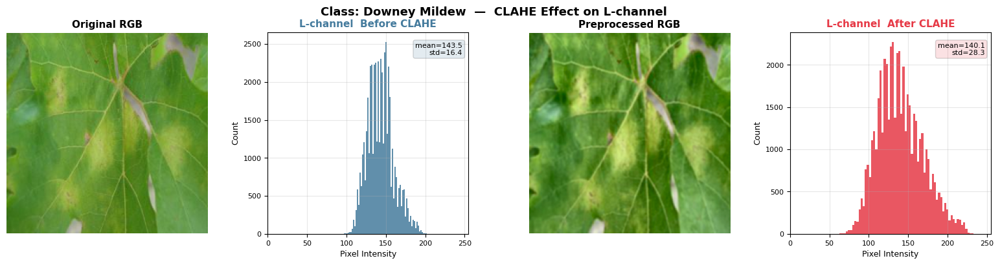


Bacterial Rot:
  L-channel before → mean=155.5  std=31.6  min=29  max=242
  L-channel after  → mean=155.2  std=37.7  min=25  max=247
  Saved: /kaggle/working/clahe_Bacterial Rot.png


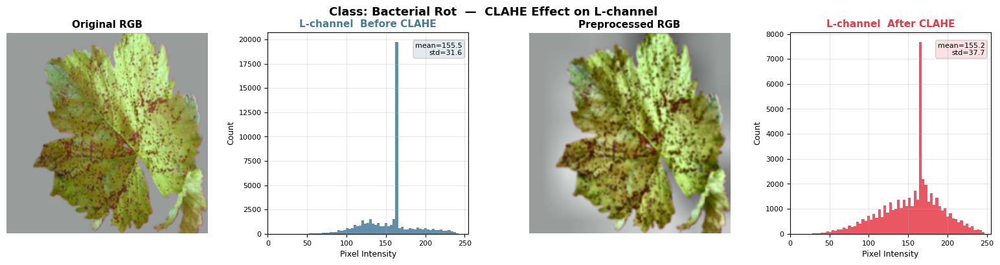


All classes done.


In [5]:
# ============================================================
# Block 2c (Fixed): L-channel histogram before vs after CLAHE
# One figure per class to avoid layout conflicts
# ============================================================

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import os
import cv2
from PIL import Image
from IPython.display import display as ipy_display, Image as IPyImage

image_exts = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

for cls in classes:
    orig_dir = os.path.join(DATA_DIR,    cls)
    proc_dir = os.path.join(PREPROC_DIR, cls)

    # pick first available image
    orig_files = sorted([f for f in os.listdir(orig_dir)
                         if f.lower().endswith(image_exts)])
    if not orig_files:
        print(f"No images found for {cls}, skipping.")
        continue

    fname = orig_files[0]

    # ── Load original ─────────────────────────────────────────
    orig_bgr = cv2.imread(os.path.join(orig_dir, fname))
    if orig_bgr is None:
        print(f"Could not read {fname}, skipping.")
        continue
    orig_bgr = cv2.resize(orig_bgr, (224, 224))
    orig_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
    l_before = cv2.split(cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2LAB))[0]

    # ── Load preprocessed ─────────────────────────────────────
    proc_name = os.path.splitext(fname)[0] + ".png"
    proc_path = os.path.join(proc_dir, proc_name)
    if not os.path.exists(proc_path):
        print(f"Preprocessed not found: {proc_path}, skipping.")
        continue
    proc_rgb = np.array(Image.open(proc_path).convert("RGB"))
    proc_bgr = cv2.cvtColor(proc_rgb, cv2.COLOR_RGB2BGR)
    l_after  = cv2.split(cv2.cvtColor(proc_bgr, cv2.COLOR_BGR2LAB))[0]

    print(f"\n{cls}:")
    print(f"  L-channel before → mean={l_before.mean():.1f}  "
          f"std={l_before.std():.1f}  "
          f"min={l_before.min()}  max={l_before.max()}")
    print(f"  L-channel after  → mean={l_after.mean():.1f}  "
          f"std={l_after.std():.1f}  "
          f"min={l_after.min()}  max={l_after.max()}")

    # ── Plot ──────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 4, figsize=(16, 4), facecolor="white")
    fig.suptitle(f"Class: {cls}  —  CLAHE Effect on L-channel",
                 fontsize=13, fontweight="bold")

    # Col 0: Original image
    axes[0].imshow(orig_rgb)
    axes[0].set_title("Original RGB", fontsize=11, fontweight="bold")
    axes[0].axis("off")

    # Col 1: L-channel histogram before
    axes[1].hist(l_before.ravel(), bins=64,
                 color="#457B9D", alpha=0.85, edgecolor="none")
    axes[1].set_title("L-channel  Before CLAHE", fontsize=11,
                       fontweight="bold", color="#457B9D")
    axes[1].set_xlim(0, 255)
    axes[1].set_xlabel("Pixel Intensity", fontsize=9)
    axes[1].set_ylabel("Count", fontsize=9)
    axes[1].grid(alpha=0.3)
    axes[1].tick_params(labelsize=8)
    # stats annotation
    axes[1].text(0.97, 0.95,
                 f"mean={l_before.mean():.1f}\nstd={l_before.std():.1f}",
                 transform=axes[1].transAxes,
                 fontsize=8, va="top", ha="right",
                 bbox=dict(boxstyle="round,pad=0.3",
                           facecolor="#457B9D", alpha=0.15))

    # Col 2: Preprocessed image
    axes[2].imshow(proc_rgb)
    axes[2].set_title("Preprocessed RGB", fontsize=11, fontweight="bold")
    axes[2].axis("off")

    # Col 3: L-channel histogram after
    axes[3].hist(l_after.ravel(), bins=64,
                 color="#E63946", alpha=0.85, edgecolor="none")
    axes[3].set_title("L-channel  After CLAHE", fontsize=11,
                       fontweight="bold", color="#E63946")
    axes[3].set_xlim(0, 255)
    axes[3].set_xlabel("Pixel Intensity", fontsize=9)
    axes[3].set_ylabel("Count", fontsize=9)
    axes[3].grid(alpha=0.3)
    axes[3].tick_params(labelsize=8)
    # stats annotation
    axes[3].text(0.97, 0.95,
                 f"mean={l_after.mean():.1f}\nstd={l_after.std():.1f}",
                 transform=axes[3].transAxes,
                 fontsize=8, va="top", ha="right",
                 bbox=dict(boxstyle="round,pad=0.3",
                           facecolor="#E63946", alpha=0.15))

    plt.subplots_adjust(wspace=0.3, left=0.03, right=0.98,
                        top=0.88, bottom=0.10)

    save_path = f"/kaggle/working/clahe_{cls}.png"
    plt.savefig(save_path, dpi=130, bbox_inches="tight",
                facecolor="white")
    print(f"  Saved: {save_path}")
    ipy_display(fig)
    plt.close(fig)

print("\nAll classes done.")

In [6]:
# ============================================================
# Block 3a (NEW): Fingerprint every image
#   - md5 of pixels            -> exact duplicates
#   - 64-bit pHash x 8 dihedral transforms -> near-duplicates that
#     were flipped / rotated (typical augmentation copies)
#   - ImageNet ResNet-18 embedding (flip-averaged) -> visually
#     similar shots of the same leaf / plant / session
# Run AFTER Block 2 (preprocessing) and BEFORE splitting.
# ============================================================

records = []
for ci, cls in enumerate(classes):
    d = os.path.join(PREPROC_DIR, cls)
    for f in sorted(os.listdir(d)):
        if f.lower().endswith(IMG_EXTS):
            records.append({"path": os.path.join(d, f), "cls": cls,
                            "label": ci, "name": f})
df = pd.DataFrame(records)
n  = len(df)
print("Images indexed:", n)
print(df.cls.value_counts().to_string(), "\n")

def phash64(gray32):
    d   = cv2.dct(gray32.astype(np.float32))[:8, :8].flatten()
    med = np.median(d[1:])
    return np.packbits(d > med).view(np.uint64)[0]

def dihedral(g):
    out = []
    for k in range(4):
        r = np.rot90(g, k)
        out += [r, np.fliplr(r)]
    return out

H   = np.zeros((n, 8), dtype=np.uint64)
md5 = []
for i, p in enumerate(df.path):
    bgr = cv2.imread(p)
    md5.append(hashlib.md5(bgr.tobytes()).hexdigest())
    g32 = cv2.resize(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY), (32, 32),
                     interpolation=cv2.INTER_AREA)
    for t, gt in enumerate(dihedral(g32)):
        H[i, t] = phash64(np.ascontiguousarray(gt))
df["md5"] = md5
print("Exact pixel-duplicates (extra copies):", int(df.md5.duplicated().sum()))

_POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def popcount64(x):
    x = np.ascontiguousarray(x)
    return _POP[x.view(np.uint8).reshape(*x.shape, 8)].sum(-1)

# ── Embeddings ────────────────────────────────────────────────
_emb_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                              transforms.Normalize([0.485, 0.456, 0.406],
                                                   [0.229, 0.224, 0.225])])
class _PathDS(Dataset):
    def __init__(self, paths): self.paths = list(paths)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return _emb_tf(Image.open(self.paths[i]).convert("RGB"))

_enc = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if PRETRAINED else None)
_enc.fc = nn.Identity()
_enc = _enc.to(device).eval()
feats = []
with torch.no_grad():
    for x in DataLoader(_PathDS(df.path), batch_size=64, num_workers=2):
        x = x.to(device)
        feats.append(((_enc(x) + _enc(torch.flip(x, [3]))) / 2).cpu())
emb = F.normalize(torch.cat(feats), dim=1).numpy().astype(np.float32)
del _enc; torch.cuda.empty_cache()
print("Embeddings:", emb.shape)

# ── Filename templates (reveals e.g. 'aug_#', 'IMG_#' sequences) ─
print("\nMost common filename templates (digits -> #):")
print(df.name.str.replace(r"\d+", "#", regex=True).value_counts().head(8).to_string())

Images indexed: 2726
cls
Healthy Leaves    1254
Downey Mildew      966
Powdery Mildew     406
Bacterial Rot      100 

Exact pixel-duplicates (extra copies): 333
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 170MB/s]


Embeddings: (2726, 512)

Most common filename templates (digits -> #):
name
Healthy Leaves_#.png         1254
Downey Mildew_#.png           966
Powdery Mildew_#.png          406
Bacterial Leaf Spot_#.png     100


pHash pairs  (<= 6 bits): 980
Embedding pairs (cos >= 0.98): 692

Groups: 1976  | multi-image groups: 567  | images in multi-image groups: 1317 (48.3%)
Largest group: 22 images
Cross-class groups (same/similar image, different label): 13 -> 75 images dropped
Exact duplicates dropped: 321
Images kept: 2330 / 2726


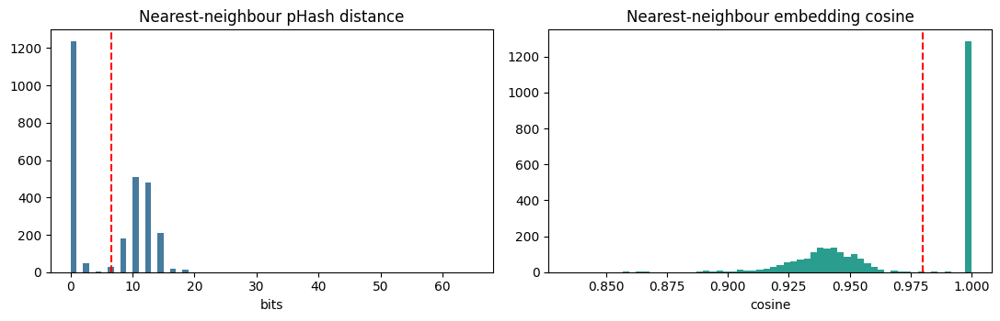

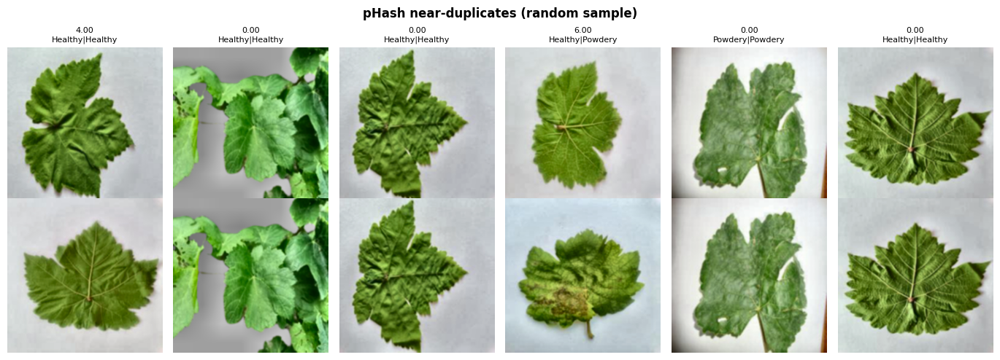

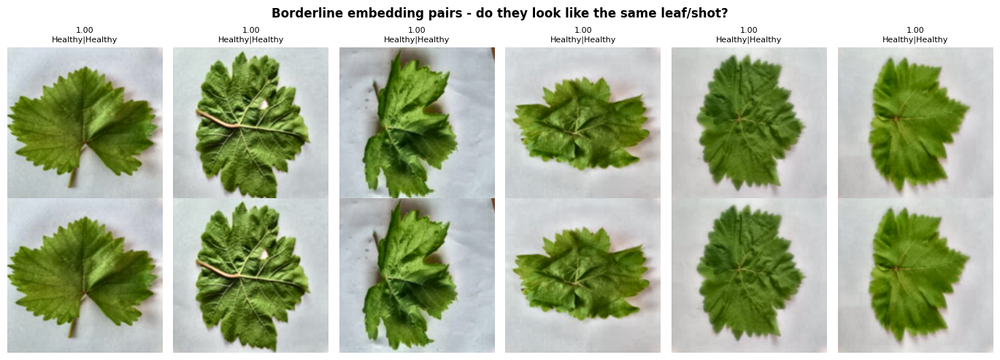

In [10]:
# ============================================================
# Block 3b (NEW): Near-duplicate groups
# Connected components over (pHash<=HASH_THR) OR (cosine>=EMB_THR).
# Every component becomes a "group" that must stay inside ONE split.
# Tune the two thresholds with the histograms / pair montage below.
# ============================================================

HASH_THR         = 6      # Hamming bits out of 64 (min over 8 flips/rotations)
EMB_THR          = 0.98   # cosine similarity of ResNet-18 embeddings
DEDUP_EXACT      = True   # drop extra copies of pixel-identical images
DROP_CROSS_CLASS = True   # drop groups whose members carry different labels

# ── pairwise pHash distances ─────────────────────────────────
hash_pairs, nn_hash = [], np.full(n, 64)
for i in range(n - 1):
    d = popcount64(H[i, 0] ^ H[i + 1:]).min(1)
    nn_hash[i]      = min(nn_hash[i], d.min())
    nn_hash[i + 1:] = np.minimum(nn_hash[i + 1:], d)
    for j in np.nonzero(d <= HASH_THR)[0]:
        hash_pairs.append((i, i + 1 + j, int(d[j])))

# ── pairwise embedding similarity (chunked) ──────────────────
emb_pairs, nn_sim = [], np.zeros(n, dtype=np.float32)
for i0 in range(0, n, 1024):
    i1 = min(i0 + 1024, n)
    S  = emb[i0:i1] @ emb.T
    S[np.arange(i1 - i0), np.arange(i0, i1)] = -1
    nn_sim[i0:i1] = S.max(1)
    r, c = np.nonzero(S >= EMB_THR)
    for a, b in zip(r + i0, c):
        if b > a: emb_pairs.append((a, b, float(S[a - i0, b])))

print(f"pHash pairs  (<= {HASH_THR} bits): {len(hash_pairs)}")
print(f"Embedding pairs (cos >= {EMB_THR}): {len(emb_pairs)}")

# ── union-find ────────────────────────────────────────────────
parent = list(range(n))
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb: parent[rb] = ra
for a, b, _ in hash_pairs: union(a, b)
for a, b, _ in emb_pairs:  union(a, b)
df["group"] = [find(i) for i in range(n)]

pairs_all = [(a, b) for a, b, _ in hash_pairs] + [(a, b) for a, b, _ in emb_pairs]
nbr = defaultdict(set)
for a, b in pairs_all:
    nbr[a].add(b); nbr[b].add(a)

# ── cleaning ──────────────────────────────────────────────────
df["keep"] = True
if DEDUP_EXACT:
    df.loc[df.md5.duplicated(keep="first"), "keep"] = False
gsz   = df.groupby("group").size()
gcls  = df.groupby("group").label.nunique()
mixed = gcls[gcls > 1].index
if DROP_CROSS_CLASS:
    df.loc[df.group.isin(mixed), "keep"] = False

print(f"\nGroups: {df.group.nunique()}  | multi-image groups: {(gsz>1).sum()}"
      f"  | images in multi-image groups: {int(gsz[gsz>1].sum())} ({100*gsz[gsz>1].sum()/n:.1f}%)")
print(f"Largest group: {gsz.max()} images")
print(f"Cross-class groups (same/similar image, different label): {len(mixed)}"
      f" -> {int(df.group.isin(mixed).sum())} images {'dropped' if DROP_CROSS_CLASS else 'kept'}")
print(f"Exact duplicates dropped: {int((~df.keep & ~df.group.isin(mixed)).sum())}")
print(f"Images kept: {int(df.keep.sum())} / {n}")
if gsz.max() > 0.05 * n:
    raise RuntimeError(f"One group holds {gsz.max()} images (>5% of data): thresholds are too loose "
                       "(chaining). Raise EMB_THR / lower HASH_THR, re-run this cell.")

# ── threshold diagnostics ─────────────────────────────────────
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), facecolor="white")
ax[0].hist(nn_hash, bins=range(0, 66), color="#457B9D"); ax[0].axvline(HASH_THR + .5, c="r", ls="--")
ax[0].set_title("Nearest-neighbour pHash distance"); ax[0].set_xlabel("bits")
ax[1].hist(nn_sim, bins=60, color="#2A9D8F"); ax[1].axvline(EMB_THR, c="r", ls="--")
ax[1].set_title("Nearest-neighbour embedding cosine"); ax[1].set_xlabel("cosine")
plt.tight_layout(); ipy_display(fig); plt.close(fig)

def show_pairs(pairs, title, k=6):
    pairs = pairs[:k]
    if not pairs: print(f"(no pairs for: {title})"); return
    fig, axes = plt.subplots(2, len(pairs), figsize=(2.3 * len(pairs), 5), facecolor="white", squeeze=False)
    for c, (a, b, s) in enumerate(pairs):
        for r, idx in enumerate((a, b)):
            axes[r, c].imshow(Image.open(df.path[idx]).convert("RGB")); axes[r, c].axis("off")
        axes[0, c].set_title(f"{s:.2f}\n{df.cls[a][:7]}|{df.cls[b][:7]}", fontsize=8)
    fig.suptitle(title, fontweight="bold"); plt.tight_layout(); ipy_display(fig); plt.close(fig)

rng = np.random.default_rng(SEED)
pick = lambda L: [L[i] for i in rng.permutation(len(L))[:6]]
show_pairs(pick(hash_pairs), "pHash near-duplicates (random sample)")
show_pairs(pick([p for p in emb_pairs if p[2] < EMB_THR + 0.02]),
           "Borderline embedding pairs - do they look like the same leaf/shot?")

In [11]:
# ============================================================
# Block 3 (REPLACES old Block 3): Group-aware stratified split 80/10/10
# No group (near-duplicate cluster) is shared between splits.
# ============================================================

SPLIT_DIR = f"{WORK_DIR}/grape_splits"
dfk = df[df.keep].copy()
dfk["uid"] = dfk.index                  # row id in the full fingerprint table
dfk = dfk.reset_index(drop=True)

def holdout(frame, n_splits, seed):
    sg = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return next(sg.split(frame, frame.label, frame.group))

dev_i, test_i = holdout(dfk, 10, SEED)                    # ~10 % test
dev = dfk.iloc[dev_i].reset_index(drop=True)
tr_i, va_i = holdout(dev, 9, SEED)                        # ~10 % of total as val
dfk["split"] = "train"
dfk.loc[dfk.uid.isin(dev.uid.iloc[va_i]), "split"] = "val"
dfk.loc[dfk.index[test_i], "split"] = "test"
split_df = dfk

# ── audit ────────────────────────────────────────────────────
g = {s: set(split_df[split_df.split == s].group) for s in ["train", "val", "test"]}
assert not (g["train"] & g["val"]) and not (g["train"] & g["test"]) and not (g["val"] & g["test"]), \
    "group leakage across splits!"
print("OK: no group is shared between train / val / test\n")
print(pd.crosstab(split_df.cls, split_df.split, margins=True).to_string(), "\n")

def leak_rate(test_uids, train_uids):
    tr = set(train_uids)
    return float(np.mean([any(j in tr for j in nbr[u]) for u in test_uids]))
def nn_cos(test_uids, train_uids):
    return (emb[list(test_uids)] @ emb[list(train_uids)].T).max(1)

# compare against the OLD style random per-class split
rand_tr, rand_te = train_test_split(split_df.uid.values, test_size=0.10,
                                    stratify=split_df.label, random_state=SEED)
grp_tr = split_df.uid[split_df.split == "train"].values
grp_te = split_df.uid[split_df.split == "test"].values
print(f"{'':28s}{'test imgs w/ near-dup in train':>32s}{'mean NN cosine test->train':>28s}")
for nm, (a, b) in {"Random split (old)": (rand_te, rand_tr), "Group split (new)": (grp_te, grp_tr)}.items():
    print(f"{nm:28s}{100*leak_rate(a, b):31.1f}%{nn_cos(a, b).mean():28.3f}")

# ── physically copy (keeps Blocks 3b-3d visualisations working) ──
if os.path.exists(SPLIT_DIR): shutil.rmtree(SPLIT_DIR)
for r in split_df.itertuples():
    out = os.path.join(SPLIT_DIR, r.split, r.cls); os.makedirs(out, exist_ok=True)
    shutil.copy(r.path, os.path.join(out, r.name))
split_df.drop(columns=["md5"]).to_csv(f"{WORK_DIR}/split_manifest.csv", index=False)
print("\nSaved split_manifest.csv")

OK: no group is shared between train / val / test

split           test  train  val   All
cls                                   
Bacterial Rot     11     80    9   100
Downey Mildew     96    769   95   960
Healthy Leaves    89    717   77   883
Powdery Mildew    37    312   38   387
All              233   1878  219  2330 

                              test imgs w/ near-dup in train  mean NN cosine test->train
Random split (old)                                     24.9%                       0.954
Group split (new)                                       0.0%                       0.942

Saved split_manifest.csv



          Class    Train     Val    Test    Total
----------------------------------------------------
 Healthy Leaves      717      77      89      883
 Powdery Mildew      312      38      37      387
  Downey Mildew      769      95      96      960
  Bacterial Rot       80       9      11      100
----------------------------------------------------
          TOTAL     1878     219     233     2330

Saved: /kaggle/working/split_bar.png


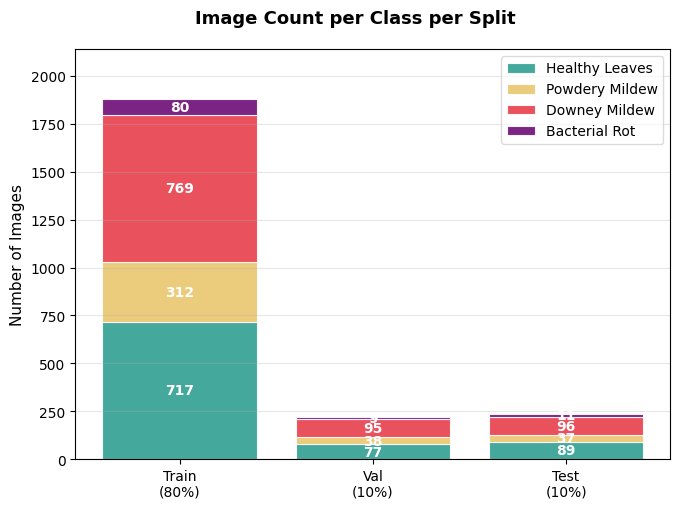

Saved: /kaggle/working/split_pie_train.png


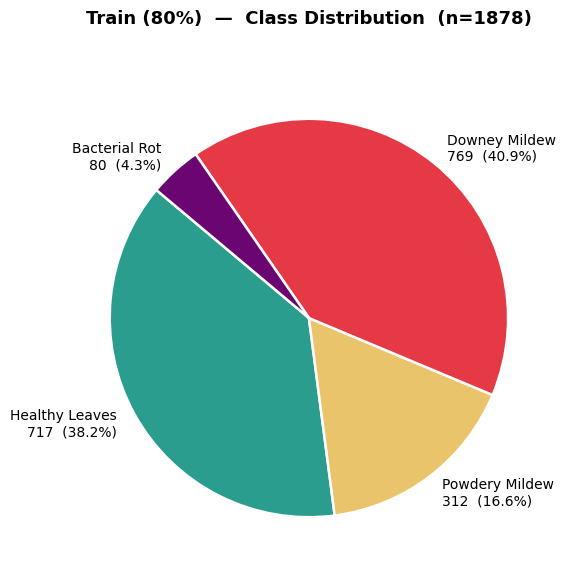

Saved: /kaggle/working/split_pie_val.png


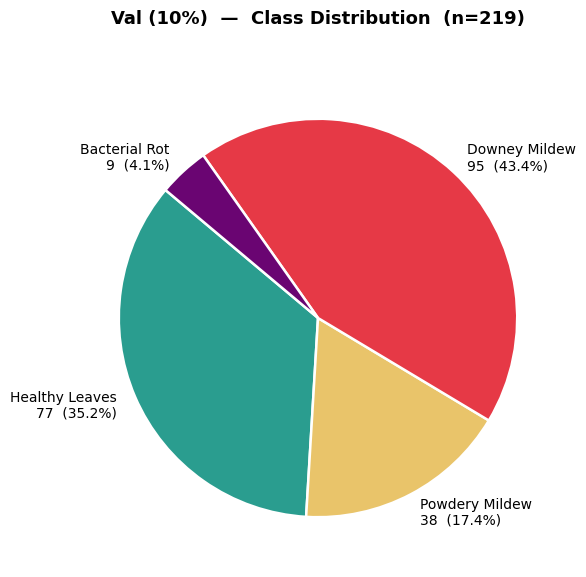

Saved: /kaggle/working/split_pie_test.png


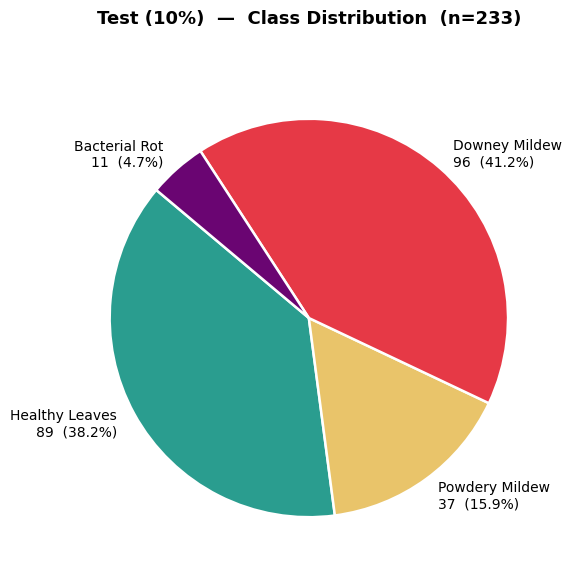


All split distribution figures done.


In [12]:
# ============================================================
# Block 3b (Fixed v2): Split Distribution
# One figure at a time + IPyImage backup
# ============================================================

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import os
from IPython.display import display as ipy_display, Image as IPyImage

image_exts = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
splits     = ["train", "val", "test"]

# ── Step 1: Count images per split per class ──────────────────
split_counts = {}
for sp in splits:
    split_counts[sp] = {}
    for cls in classes:
        p = os.path.join(SPLIT_DIR, sp, cls)
        n = len([f for f in os.listdir(p)
                 if f.lower().endswith(image_exts)]) \
            if os.path.isdir(p) else 0
        split_counts[sp][cls] = n

# ── Step 2: Print table ───────────────────────────────────────
print(f"\n{'Class':>15}  {'Train':>7}  {'Val':>6}  {'Test':>6}  {'Total':>7}")
print("-" * 52)
for cls in classes:
    tr = split_counts["train"][cls]
    va = split_counts["val"][cls]
    te = split_counts["test"][cls]
    print(f"{cls:>15}  {tr:>7}  {va:>6}  {te:>6}  {tr+va+te:>7}")
tr_tot = sum(split_counts["train"].values())
va_tot = sum(split_counts["val"].values())
te_tot = sum(split_counts["test"].values())
print("-" * 52)
print(f"{'TOTAL':>15}  {tr_tot:>7}  {va_tot:>6}  {te_tot:>6}  "
      f"{tr_tot+va_tot+te_tot:>7}")

colors_cls   = ["#2A9D8F", "#E9C46A", "#E63946", "#6A0572"]
split_labels = ["Train\n(80%)", "Val\n(10%)", "Test\n(10%)"]

# ============================================================
# Figure 1: Stacked Bar Chart
# ============================================================
fig1, ax = plt.subplots(figsize=(7, 5), facecolor="white")
fig1.suptitle("Image Count per Class per Split",
              fontsize=13, fontweight="bold")

bottom_vals = np.zeros(3)
for ci, cls in enumerate(classes):
    vals = [split_counts[sp][cls] for sp in splits]
    bars = ax.bar(split_labels, vals, bottom=bottom_vals,
                  color=colors_cls[ci], label=cls,
                  alpha=0.88, edgecolor="white", linewidth=0.8)
    for bar, v, bot in zip(bars, vals, bottom_vals):
        if v > 8:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bot + v / 2,
                str(v),
                ha="center", va="center",
                fontsize=10, fontweight="bold", color="white"
            )
    bottom_vals += np.array(vals, dtype=float)

ax.set_ylabel("Number of Images", fontsize=11)
ax.legend(loc="upper right", fontsize=10, framealpha=0.7)
ax.grid(axis="y", alpha=0.3)
ax.set_ylim(0, max(bottom_vals) * 1.14)
ax.tick_params(axis="x", labelsize=10)

plt.subplots_adjust(left=0.10, right=0.95,
                    top=0.90, bottom=0.08)

save1 = "/kaggle/working/split_bar.png"
fig1.savefig(save1, dpi=130, bbox_inches="tight", facecolor="white")
print(f"\nSaved: {save1}")
ipy_display(fig1)
plt.close(fig1)

# ============================================================
# Figure 2: Pie Charts — one per split
# ============================================================
for sp, lbl in zip(splits, ["Train (80%)", "Val (10%)", "Test (10%)"]):
    vals  = [split_counts[sp][cls] for cls in classes]
    total = sum(vals)

    fig2, ax2 = plt.subplots(figsize=(6, 6), facecolor="white")
    fig2.suptitle(f"{lbl}  —  Class Distribution  (n={total})",
                  fontsize=13, fontweight="bold")

    w_lbls = [f"{cls}\n{v}  ({100*v/total:.1f}%)"
              for cls, v in zip(classes, vals)]

    wedges, texts = ax2.pie(
        vals,
        labels     = w_lbls,
        colors     = colors_cls,
        startangle = 140,
        wedgeprops = {"edgecolor": "white", "linewidth": 1.8},
        textprops  = {"fontsize": 10},
    )

    plt.subplots_adjust(left=0.05, right=0.95,
                        top=0.88, bottom=0.05)

    save2 = f"/kaggle/working/split_pie_{sp}.png"
    fig2.savefig(save2, dpi=130, bbox_inches="tight", facecolor="white")
    print(f"Saved: {save2}")
    ipy_display(fig2)
    plt.close(fig2)

print("\nAll split distribution figures done.")


Building grid for: TRAIN split ...
  Healthy Leaves : 717 images found
  Powdery Mildew : 312 images found
  Downey Mildew  : 769 images found
  Bacterial Rot  : 80 images found
  Grid shape: (448, 448, 3)
  Saved: /kaggle/working/split_samples_train.png


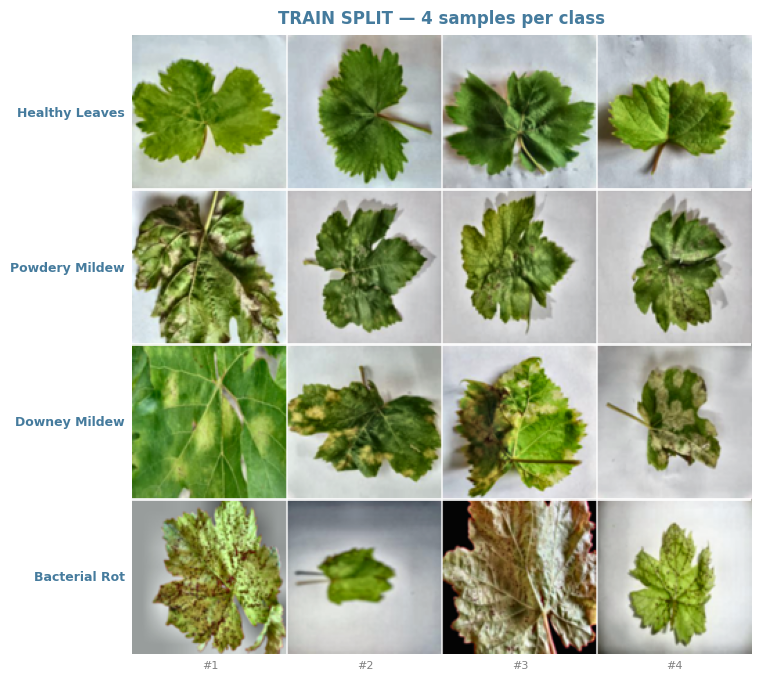


Building grid for: VAL split ...
  Healthy Leaves : 77 images found
  Powdery Mildew : 38 images found
  Downey Mildew  : 95 images found
  Bacterial Rot  : 9 images found
  Grid shape: (448, 448, 3)
  Saved: /kaggle/working/split_samples_val.png


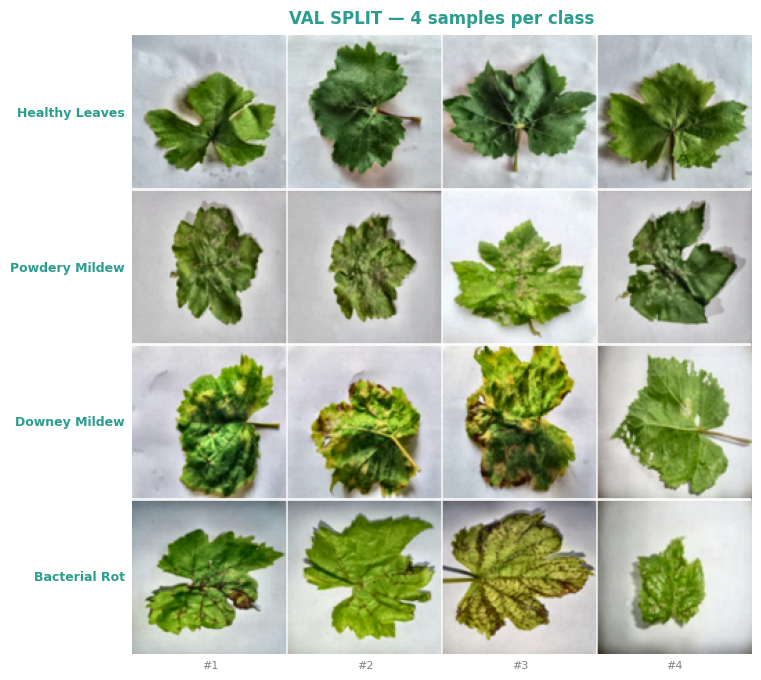


Building grid for: TEST split ...
  Healthy Leaves : 89 images found
  Powdery Mildew : 37 images found
  Downey Mildew  : 96 images found
  Bacterial Rot  : 11 images found
  Grid shape: (448, 448, 3)
  Saved: /kaggle/working/split_samples_test.png


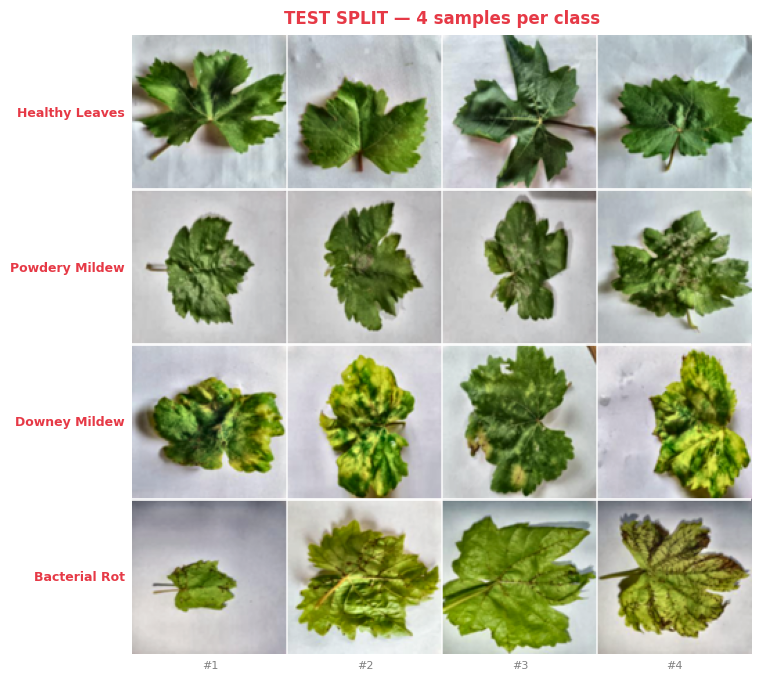


All split sample grids done.


In [13]:
# ============================================================
# Block 3c (Fixed v2): Sample Image Grid from Each Split
# One split at a time + IPyImage backup
# ============================================================

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import os
from PIL import Image
from IPython.display import display as ipy_display, Image as IPyImage

image_exts = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
splits      = ["train", "val", "test"]
n_per_class = 4
split_colors = {"train": "#457B9D", "val": "#2A9D8F", "test": "#E63946"}

for sp in splits:
    print(f"\nBuilding grid for: {sp.upper()} split ...")

    # ── collect images ────────────────────────────────────────
    rows = []
    row_labels = []
    all_ok = True

    for cls in classes:
        cls_dir = os.path.join(SPLIT_DIR, sp, cls)
        files   = sorted([f for f in os.listdir(cls_dir)
                          if f.lower().endswith(image_exts)])

        print(f"  {cls:15s}: {len(files)} images found")

        row_imgs = []
        for fname in files[:n_per_class]:
            fpath = os.path.join(cls_dir, fname)
            try:
                img = np.array(
                    Image.open(fpath).convert("RGB").resize((112, 112))
                )
                row_imgs.append(img)
            except Exception as e:
                print(f"    WARNING: {fname} — {e}")

        # pad with black if fewer images than n_per_class
        while len(row_imgs) < n_per_class:
            row_imgs.append(np.zeros((112, 112, 3), dtype=np.uint8))

        row_strip = np.concatenate(row_imgs, axis=1)   # (112, 112*n, 3)
        rows.append(row_strip)
        row_labels.append(cls)

    if not rows:
        print(f"  No rows built for {sp}, skipping.")
        continue

    grid = np.concatenate(rows, axis=0)    # (112*n_cls, 112*n_per_class, 3)
    print(f"  Grid shape: {grid.shape}")

    # ── plot ──────────────────────────────────────────────────
    n_cls  = len(classes)
    fig, ax = plt.subplots(
        figsize=(n_per_class * 1.8, n_cls * 1.8 + 0.8),
        facecolor="white"
    )

    ax.imshow(grid)
    ax.axis("off")
    ax.set_title(f"{sp.upper()} SPLIT — {n_per_class} samples per class",
                 fontsize=12, fontweight="bold",
                 color=split_colors[sp], pad=8)

    # class row labels on y-axis
    for ri, cls in enumerate(row_labels):
        ax.text(
            -6, ri * 112 + 56,
            cls,
            va="center", ha="right",
            fontsize=9, fontweight="bold",
            color=split_colors[sp],
            transform=ax.transData
        )

    # column index labels on x-axis
    for ci in range(n_per_class):
        ax.text(
            ci * 112 + 56, n_cls * 112 + 4,
            f"#{ci+1}",
            va="top", ha="center",
            fontsize=8, color="grey",
            transform=ax.transData
        )

    # horizontal dividers between class rows
    for ri in range(1, n_cls):
        ax.axhline(y=ri * 112 - 0.5,
                   color="white", linewidth=2, alpha=0.9)

    # vertical dividers between images
    for ci in range(1, n_per_class):
        ax.axvline(x=ci * 112 - 0.5,
                   color="white", linewidth=1.5, alpha=0.7)

    plt.subplots_adjust(left=0.12, right=0.98,
                        top=0.93,  bottom=0.03)

    save_path = f"/kaggle/working/split_samples_{sp}.png"
    fig.savefig(save_path, dpi=130, bbox_inches="tight",
                facecolor="white")
    print(f"  Saved: {save_path}")
    ipy_display(fig)
    plt.close(fig)

print("\nAll split sample grids done.")

In [14]:
# ============================================================
# Block 3d: Class Imbalance — Before vs After Weighted Sampling
# Shows WHY we need focal loss + weighted sampler
# Useful figure for the paper's methodology section
# ============================================================

def show_class_imbalance(split_dir, classes, save_path=None):
    image_exts = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

    train_counts = []
    for cls in classes:
        p = os.path.join(split_dir, "train", cls)
        n = len([f for f in os.listdir(p)
                 if f.lower().endswith(image_exts)])
        train_counts.append(n)

    total       = sum(train_counts)
    freq_before = [c / total for c in train_counts]
    freq_after  = [1.0 / len(classes)] * len(classes)   # after oversampling

    colors_cls = ["#2A9D8F", "#E9C46A", "#E63946", "#6A0572"]

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle("Class Imbalance in Training Set & Weighted Sampling Effect",
                 fontsize=13, fontweight="bold")

    # ── Bar: raw counts ───────────────────────────────────────
    ax = axes[0]
    bars = ax.bar(classes, train_counts, color=colors_cls,
                   edgecolor="white", linewidth=0.8)
    ax.set_title("Raw Image Counts (Train)", fontweight="bold")
    ax.set_ylabel("Number of Images")
    ax.set_xticklabels(classes, rotation=20, ha="right")
    for bar, cnt in zip(bars, train_counts):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 5, str(cnt),
                ha="center", fontsize=10, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)

    # ── Bar: sampling frequency before/after ──────────────────
    ax   = axes[1]
    x    = np.arange(len(classes))
    w    = 0.35
    ax.bar(x - w/2, freq_before, w, label="Before Sampling",
            color="#457B9D", alpha=0.85)
    ax.bar(x + w/2, freq_after,  w, label="After Weighted Sampling",
            color="#E63946", alpha=0.85)
    ax.axhline(1.0/len(classes), color="grey", ls="--", lw=1.2,
                label=f"Ideal ({1/len(classes):.2f})")
    ax.set_title("Sampling Frequency per Class", fontweight="bold")
    ax.set_ylabel("Relative Frequency")
    ax.set_xticks(x)
    ax.set_xticklabels(classes, rotation=20, ha="right")
    ax.legend(fontsize=9); ax.grid(axis="y", alpha=0.3)

    # ── Pie: raw distribution ──────────────────────────────────
    ax = axes[2]
    wedge_labels = [f"{cls}\n{cnt}\n({100*cnt/total:.1f}%)"
                    for cls, cnt in zip(classes, train_counts)]
    ax.pie(train_counts, labels=wedge_labels, colors=colors_cls,
            startangle=140,
            wedgeprops={"edgecolor": "white", "linewidth": 1.5},
            textprops={"fontsize": 9})
    ax.set_title("Class Distribution in Train Set", fontweight="bold")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()

    # Print imbalance ratio
    print(f"\nClass Imbalance Ratio (max/min): "
          f"{max(train_counts)/min(train_counts):.1f}:1")
    print("This justifies Focal Loss + WeightedRandomSampler in AGCTNet.")


show_class_imbalance(
    split_dir = SPLIT_DIR,
    classes   = classes,
    save_path = "/kaggle/working/class_imbalance.png"
)

Saved: /kaggle/working/class_imbalance.png

Class Imbalance Ratio (max/min): 9.6:1
This justifies Focal Loss + WeightedRandomSampler in AGCTNet.


In [15]:
# ============================================================
# Block 3e (NEW): Shortcut / background-bias probe
# Frozen ImageNet ResNet-18 features + logistic regression, trained on
# the TRAIN split, scored on TEST, for three views of each image:
#   full | centre-only (borders greyed) | corners-only (centre greyed)
# If corners-only is far above chance (0.25 balanced acc), class
# information leaks through context/background or leaf coverage,
# not only through the lesion. Interpret together with Grad-CAM.
# ============================================================
from sklearn.linear_model import LogisticRegression

GREY = (124, 116, 104)
def view_full(a): return a
def view_centre(a):
    o = np.empty_like(a); o[:] = GREY; o[56:168, 56:168] = a[56:168, 56:168]; return o
def view_corners(a):
    o = np.empty_like(a); o[:] = GREY
    for ys in (slice(0, 70), slice(154, 224)):
        for xs in (slice(0, 70), slice(154, 224)):
            o[ys, xs] = a[ys, xs]
    return o

_probe = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if PRETRAINED else None)
_probe.fc = nn.Identity(); _probe = _probe.to(device).eval()
_m = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); _s = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

@torch.no_grad()
def probe_feats(paths, view, bs=64):
    out = []
    for i in range(0, len(paths), bs):
        arr = np.stack([view(np.array(Image.open(p).convert("RGB").resize((224, 224)))) for p in paths[i:i+bs]])
        x = (torch.from_numpy(arr).permute(0, 3, 1, 2).float() / 255 - _m) / _s
        out.append(_probe(x.to(device)).cpu().numpy())
    return np.concatenate(out)

tr_m, te_m = split_df.split == "train", split_df.split == "test"
rows = []
for nm, vw in {"full": view_full, "centre-only": view_centre, "corners-only": view_corners}.items():
    Xtr = probe_feats(split_df.path[tr_m].tolist(), vw); Xte = probe_feats(split_df.path[te_m].tolist(), vw)
    clf = LogisticRegression(max_iter=3000, class_weight="balanced").fit(Xtr, split_df.label[tr_m])
    p = clf.predict(Xte); y = split_df.label[te_m]
    rows.append({"view": nm, "accuracy": accuracy_score(y, p),
                 "balanced_acc": balanced_accuracy_score(y, p), "macro_F1": f1_score(y, p, average="macro")})
del _probe; torch.cuda.empty_cache()
print(pd.DataFrame(rows).round(4).to_string(index=False))
print("\nChance balanced accuracy = 0.25. A corners-only score close to 'full' is a red flag for context shortcuts.")

        view  accuracy  balanced_acc  macro_F1
        full    0.9442        0.9327    0.9441
 centre-only    0.9356        0.9236    0.9313
corners-only    0.9099        0.8590    0.8890

Chance balanced accuracy = 0.25. A corners-only score close to 'full' is a red flag for context shortcuts.


In [17]:
# ============================================================
# Block 4 (Updated): Datasets, Transforms, Loaders
# Built from split_df (group-aware). Adds an un-augmented
# train_eval_loader so "train accuracy" is measured fairly.
# ============================================================
IMNET_MEAN, IMNET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(IMNET_MEAN, IMNET_STD),
])
val_test_tf = transforms.Compose([
    transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize(IMNET_MEAN, IMNET_STD),
])

class GrapeDataset(Dataset):
    """samples = list of (path, label)"""
    def __init__(self, samples, transform):
        self.samples, self.transform = list(samples), transform
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        p, y = self.samples[i]
        return self.transform(Image.open(p).convert("RGB")), y

def samples_of(frame): return list(zip(frame.path, frame.label.astype(int)))
BATCH = 32

def make_loaders(tr, va, te=None, batch=BATCH):
    """tr/va/te: lists of (path,label). Returns dict of loaders."""
    cnt = np.bincount([y for _, y in tr], minlength=num_classes)
    w   = [1.0 / cnt[y] for _, y in tr]
    kw  = dict(num_workers=2, pin_memory=True, worker_init_fn=seed_worker)
    L = {
      "train":      DataLoader(GrapeDataset(tr, train_tf), batch_size=batch,
                               sampler=WeightedRandomSampler(w, len(tr), replacement=True), **kw),
      "train_eval": DataLoader(GrapeDataset(tr, val_test_tf), batch_size=batch, shuffle=False, **kw),
      "val":        DataLoader(GrapeDataset(va, val_test_tf), batch_size=batch, shuffle=False, **kw),
    }
    if te is not None:
        L["test"] = DataLoader(GrapeDataset(te, val_test_tf), batch_size=batch, shuffle=False, **kw)
    return L

train_df = split_df[split_df.split == "train"].reset_index(drop=True)
val_df   = split_df[split_df.split == "val"].reset_index(drop=True)
test_df  = split_df[split_df.split == "test"].reset_index(drop=True)
loaders  = make_loaders(samples_of(train_df), samples_of(val_df), samples_of(test_df))
train_loader, train_eval_loader = loaders["train"], loaders["train_eval"]
val_loader, test_loader         = loaders["val"],   loaders["test"]
test_ds = test_loader.dataset
print(f"Train {len(train_df)} | Val {len(val_df)} | Test {len(test_df)}")
print("Train class counts:", np.bincount(train_df.label, minlength=num_classes).tolist())

Train 1878 | Val 219 | Test 233
Train class counts: [717, 312, 769, 80]


In [18]:
# ============================================================
# Block 5: Focal Loss
# Focal loss down-weights easy majority-class examples,
# focusing learning on hard / minority samples.
# Standard CE cannot handle 12:1 Healthy:BacterialRot ratio.
# ============================================================

class FocalLoss(nn.Module):
    """
    Multi-class focal loss.
    FL(p_t) = -alpha_t * (1 - p_t)^gamma * log(p_t)
    """
    def __init__(self, gamma: float = 2.0, label_smoothing: float = 0.05):
        super().__init__()
        self.gamma           = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits: torch.Tensor, targets: torch.Tensor):
        # Label-smoothed log-softmax
        n_cls = logits.size(1)
        with torch.no_grad():
            smooth_val  = self.label_smoothing / n_cls
            target_dist = torch.full_like(logits, smooth_val)
            target_dist.scatter_(1, targets.unsqueeze(1),
                                 1.0 - self.label_smoothing + smooth_val)

        log_p  = F.log_softmax(logits, dim=1)
        p      = log_p.exp()

        # Focal weight based on true-class probability
        pt     = (p * target_dist).sum(dim=1)
        weight = (1.0 - pt) ** self.gamma

        loss   = -(target_dist * log_p).sum(dim=1)
        return (weight * loss).mean()


criterion = FocalLoss(gamma=2.0, label_smoothing=0.05)
print("FocalLoss criterion ready.")

FocalLoss criterion ready.


In [19]:
# ============================================================
# Block 6 (Updated): Train / Evaluate / Predict helpers
# DELETE the old 'partial_freeze' helper cell - it is not used any more.
# ============================================================
USE_AMP = device.type == "cuda"
try:    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
except Exception: scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    run_loss, run_correct, n = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            out = model(imgs)
        loss = criterion(out.float(), labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        scaler.step(optimizer); scaler.update()
        run_loss    += loss.item() * imgs.size(0)
        run_correct += (out.argmax(1) == labels).sum().item()
        n           += imgs.size(0)
    return run_loss / n, run_correct / n

@torch.no_grad()
def predict(model, loader, device, criterion=None):
    """Returns dict: y_true, y_pred, probs, loss, ms_per_img"""
    model.eval()
    yt, yp, pr, loss_sum, n, t_sum, t_n = [], [], [], 0.0, 0, 0.0, 0
    for bi, (imgs, labels) in enumerate(loader):
        imgs = imgs.to(device)
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        out = model(imgs).float()
        if device.type == "cuda": torch.cuda.synchronize()
        if bi > 0 or len(loader) == 1:               # skip first batch (warm-up)
            t_sum += time.perf_counter() - t0; t_n += imgs.size(0)
        if criterion is not None:
            loss_sum += criterion(out, labels.to(device)).item() * imgs.size(0)
        n += imgs.size(0)
        pr.append(F.softmax(out, 1).cpu().numpy()); yp.append(out.argmax(1).cpu().numpy()); yt.append(labels.numpy())
    pr = np.concatenate(pr)
    return {"y_true": np.concatenate(yt), "y_pred": np.concatenate(yp), "probs": pr,
            "loss": loss_sum / max(n, 1), "ms_per_img": 1000 * t_sum / max(t_n, 1)}

def evaluate(model, loader, criterion, device):
    r = predict(model, loader, device, criterion)
    return r["loss"], accuracy_score(r["y_true"], r["y_pred"]), f1_score(r["y_true"], r["y_pred"], average="macro")

def get_preds_with_time(model, loader, device):
    r = predict(model, loader, device)
    return r["y_true"], r["y_pred"], r["ms_per_img"]

print("Training utilities ready.")

Training utilities ready.


In [20]:
# ============================================================
# Block 7 (Updated): Training loop - warm-up + cosine, early stopping
# Identical protocol is used for EVERY model (baselines and AGCTNet).
# ============================================================
CKPT_DIR = f"{WORK_DIR}/ckpt"; os.makedirs(CKPT_DIR, exist_ok=True)

def train_model(model, model_name, train_loader, val_loader, criterion,
                num_epochs=30, patience=6, lr=3e-4, weight_decay=1e-2,
                warmup=2, eta_min=1e-6, verbose=True):
    seed_everything()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    def lam(ep):
        if ep < warmup: return (ep + 1) / warmup
        prog = (ep - warmup) / max(1, num_epochs - warmup)
        return max(eta_min / lr, 0.5 * (1 + math.cos(math.pi * prog)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lam)

    path = f"{CKPT_DIR}/{model_name}.pth"
    best, bad = float("inf"), 0
    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": [], "lr": []}
    h["best_epoch"] = 0
    if verbose: print(f"\n{'='*60}\n  Training {model_name}  (lr={lr:g})\n{'='*60}")
    for ep in range(1, num_epochs + 1):
        tl, ta = train_one_epoch(model, train_loader, opt, criterion, device)
        vl, va, vf = evaluate(model, val_loader, criterion, device)
        h["lr"].append(opt.param_groups[0]["lr"]); sched.step()
        for k, v in zip(["train_loss", "val_loss", "train_acc", "val_acc", "val_f1"], [tl, vl, ta, va, vf]):
            h[k].append(float(v))
        flag = ""
        if vl < best - 1e-4:
            best, bad, h["best_epoch"] = vl, 0, ep
            torch.save(model.state_dict(), path); flag = " *"
        else:
            bad += 1
        if verbose:
            print(f"Ep {ep:02d}/{num_epochs} tr {tl:.4f}/{ta:.4f} | va {vl:.4f}/{va:.4f} f1 {vf:.4f}{flag}")
        if bad >= patience:
            if verbose: print(f"Early stop at epoch {ep}")
            break
    h["stopped_epoch"] = ep
    model.load_state_dict(torch.load(path, map_location=device))
    return model, h, path

print("train_model() ready.")

train_model() ready.


In [21]:
# ============================================================
# Block 8 (NEW - replaces ResNet / SqueezeNet / ViT / DeiT / AGCTNet
# cells). EVERY model is fully fine-tuned. No freezing, no
# 'if accuracy too high, shrink the head' logic, no 'expected
# accuracy' targets.
# ============================================================
def disable_inplace(model):
    """In-place ReLU/Dropout break hooks & Grad-CAM; harmless to turn off."""
    for m in model.modules():
        if hasattr(m, "inplace"): m.inplace = False
    return model

def build_resnet18():
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if PRETRAINED else None)
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, num_classes)); return m

def build_squeezenet():
    m = models.squeezenet1_1(weights=models.SqueezeNet1_1_Weights.IMAGENET1K_V1 if PRETRAINED else None)
    # no ReLU on the logits (the old head clipped negative logits)
    m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Conv2d(512, num_classes, 1),
                                 nn.AdaptiveAvgPool2d(1), nn.Flatten()); return m

def build_efficientnet_b0():     # extra, stronger lightweight baseline
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if PRETRAINED else None)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes); return m

def build_vit_tiny():
    return timm.create_model("vit_tiny_patch16_224", pretrained=PRETRAINED, num_classes=num_classes, drop_rate=0.1)

def build_deit_tiny():
    return timm.create_model("deit_tiny_patch16_224", pretrained=PRETRAINED, num_classes=num_classes, drop_rate=0.1)

class ChannelAttentionGate(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        r = max(channels // reduction, 8)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(nn.Linear(channels, r, bias=False), nn.ReLU(),
                                nn.Linear(r, channels, bias=False), nn.Sigmoid())
    def forward(self, x):
        b, c, _, _ = x.shape
        return x * self.fc(self.pool(x).view(b, c)).view(b, c, 1, 1)

class AGCTNet(nn.Module):
    """Dual-branch (SqueezeNet1.1 + DeiT-Tiny) -> fusion -> CAG -> Transformer.
    The use_* flags create the ablation variants from the SAME code, so
    ablation and main model can never drift apart."""
    def __init__(self, num_classes=4, d_model=256, n_heads=8, n_layers=3, dropout=0.3,
                 use_cnn=True, use_deit=True, use_cag=True, use_transformer=True):
        super().__init__()
        assert use_cnn or use_deit
        self.use_cnn, self.use_deit, self.use_cag, self.use_tf = use_cnn, use_deit, use_cag, use_transformer
        ch = 0
        if use_cnn:
            sq = models.squeezenet1_1(weights=models.SqueezeNet1_1_Weights.IMAGENET1K_V1 if PRETRAINED else None)
            self.cnn_branch = sq.features; self.cnn_align = nn.AdaptiveAvgPool2d((7, 7)); ch += 512
        if use_deit:
            self.tr_branch = timm.create_model("deit_tiny_patch16_224", pretrained=PRETRAINED, num_classes=0)
            self.tr_spatial = nn.Sequential(nn.Linear(192, 192 * 49, bias=False), nn.GELU()); ch += 192
        self.fuse_proj = nn.Sequential(nn.Conv2d(ch, d_model * 2, 1, bias=False),
                                       nn.BatchNorm2d(d_model * 2), nn.GELU())
        if use_cag: self.cag = ChannelAttentionGate(d_model * 2, 16)
        if use_transformer:
            self.patch_proj = nn.Conv2d(d_model * 2, d_model, 1)
            self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
            self.pos_embed = nn.Parameter(torch.zeros(1, 50, d_model))
            nn.init.trunc_normal_(self.cls_token, std=0.02); nn.init.trunc_normal_(self.pos_embed, std=0.02)
            enc = nn.TransformerEncoderLayer(d_model, n_heads, d_model * 4, dropout,
                                             batch_first=True, norm_first=True)
            self.transformer = nn.TransformerEncoder(enc, n_layers, enable_nested_tensor=False)
            self.norm = nn.LayerNorm(d_model); feat = d_model
            nn.init.xavier_uniform_(self.patch_proj.weight)
        else:
            self.pool = nn.AdaptiveAvgPool2d(1); feat = d_model * 2
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(feat, num_classes))
        nn.init.xavier_uniform_(self.fuse_proj[0].weight)

    def forward(self, x):
        B, fs = x.size(0), []
        if self.use_cnn:  fs.append(self.cnn_align(self.cnn_branch(x)))
        if self.use_deit: fs.append(self.tr_spatial(self.tr_branch(x)).view(B, 192, 7, 7))
        fused = self.fuse_proj(torch.cat(fs, 1))
        if self.use_cag: fused = self.cag(fused)
        if not self.use_tf: return self.head(self.pool(fused).flatten(1))
        tok = self.patch_proj(fused).flatten(2).permute(0, 2, 1)
        tok = torch.cat([self.cls_token.expand(B, -1, -1), tok], 1) + self.pos_embed
        return self.head(self.norm(self.transformer(tok)[:, 0]))

def build_agctnet(**kw): return AGCTNet(num_classes, **kw)

MODEL_BUILDERS = {"ResNet-18": build_resnet18, "SqueezeNet1.1": build_squeezenet,
                  "EfficientNet-B0": build_efficientnet_b0, "ViT-Tiny": build_vit_tiny,
                  "DeiT-Tiny": build_deit_tiny, "AGCTNet": build_agctnet}
# same budget (3 learning rates) for every model; grids match each family
LR_GRIDS = {"ResNet-18": [1e-4, 3e-4, 1e-3], "SqueezeNet1.1": [1e-4, 3e-4, 1e-3],
            "EfficientNet-B0": [1e-4, 3e-4, 1e-3], "ViT-Tiny": [2e-5, 5e-5, 1e-4],
            "DeiT-Tiny": [2e-5, 5e-5, 1e-4], "AGCTNet": [5e-5, 1e-4, 3e-4]}

def build_model(name, **kw):
    return disable_inplace(MODEL_BUILDERS[name](**kw)).to(device)

for nm in MODEL_BUILDERS:
    m = build_model(nm)
    p = sum(q.numel() for q in m.parameters()); t = sum(q.numel() for q in m.parameters() if q.requires_grad)
    with torch.no_grad(): o = m.eval()(torch.randn(2, 3, 224, 224, device=device))
    print(f"{nm:16s} params {p/1e6:6.2f}M | trainable {t/1e6:6.2f}M (100% -> {t==p}) | out {tuple(o.shape)}")
    del m

ResNet-18        params  11.18M | trainable  11.18M (100% -> True) | out (2, 4)
Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to /root/.cache/torch/hub/checkpoints/squeezenet1_1-b8a52dc0.pth


100%|██████████| 4.73M/4.73M [00:00<00:00, 123MB/s]

SqueezeNet1.1    params   0.72M | trainable   0.72M (100% -> True) | out (2, 4)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 226MB/s]


EfficientNet-B0  params   4.01M | trainable   4.01M (100% -> True) | out (2, 4)


... (2 outputs left out)

ViT-Tiny         params   5.53M | trainable   5.53M (100% -> True) | out (2, 4)


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.9MB            

model.safetensors: downloading bytes:           |  0.00B            

DeiT-Tiny        params   5.53M | trainable   5.53M (100% -> True) | out (2, 4)
AGCTNet          params  10.96M | trainable  10.96M (100% -> True) | out (2, 4)


In [22]:
# ============================================================
# Block 10 (NEW): Equal-budget tuning + training of ALL models
# - each model gets 3 learning rates (own family grid)
# - choose by VALIDATION macro-F1 (tie -> lower val loss)
# - the TEST set is not touched here
# - resumable: finished runs are skipped after a Kaggle restart
# ============================================================
TUNE_EPOCHS, TUNE_PATIENCE = 30, 6
safe = lambda s: s.replace("-", "_").replace(".", "_").replace(" ", "_")
assert "criterion" in globals(), "run Block 5 (FocalLoss / criterion) first"

LOG = f"{WORK_DIR}/tuning_log.json"
tlog = json.load(open(LOG)) if os.path.exists(LOG) else {}

for name in MODEL_BUILDERS:
    for lr in LR_GRIDS[name]:
        run = f"{safe(name)}_lr{lr:g}"; ck = f"{CKPT_DIR}/{run}.pth"
        if run in tlog and os.path.exists(ck):
            print(f"skip {run} (done): val_f1={tlog[run]['val_f1']:.4f}"); continue
        model = build_model(name)
        model, h, _ = train_model(model, run, train_loader, val_loader, criterion,
                                  num_epochs=TUNE_EPOCHS, patience=TUNE_PATIENCE, lr=lr)
        vl, va, vf = evaluate(model, val_loader, criterion, device)
        tlog[run] = {"model": name, "lr": lr, "val_loss": vl, "val_acc": va, "val_f1": vf,
                     "ckpt": ck, "hist": h}
        json.dump(tlog, open(LOG, "w"))
        del model; torch.cuda.empty_cache()

best_run, best_lr, model_registry, hist_registry = {}, {}, {}, {}
rows = []
for name in MODEL_BUILDERS:
    runs = [r for r in tlog.values() if r["model"] == name]
    b = sorted(runs, key=lambda r: (-round(r["val_f1"], 4), r["val_loss"]))[0]
    best_run[name], best_lr[name] = b["ckpt"], b["lr"]
    m = build_model(name); m.load_state_dict(torch.load(b["ckpt"], map_location=device)); m.eval()
    model_registry[name], hist_registry[name] = m, b["hist"]
    for r in runs: rows.append({"Model": name, "LR": r["lr"], "Val_loss": round(r["val_loss"], 4),
                                "Val_acc": round(r["val_acc"], 4), "Val_F1": round(r["val_f1"], 4),
                                "Selected": r["lr"] == b["lr"]})
df_tune = pd.DataFrame(rows); df_tune.to_csv(f"{WORK_DIR}/tuning_results.csv", index=False)
print("\n", df_tune.to_string(index=False))


  Training ResNet_18_lr0.0001  (lr=0.0001)
Ep 01/30 tr 0.3247/0.7476 | va 0.1073/0.9361 f1 0.9169 *
Ep 02/30 tr 0.0839/0.9388 | va 0.0875/0.9589 f1 0.9383 *
Ep 03/30 tr 0.0495/0.9617 | va 0.0747/0.9498 f1 0.9393 *
Ep 04/30 tr 0.0350/0.9686 | va 0.0506/0.9680 f1 0.9401 *
Ep 05/30 tr 0.0316/0.9739 | va 0.0726/0.9543 f1 0.9312
Ep 06/30 tr 0.0315/0.9718 | va 0.0491/0.9772 f1 0.9640 *
Ep 07/30 tr 0.0300/0.9792 | va 0.0297/0.9817 f1 0.9586 *
Ep 08/30 tr 0.0196/0.9814 | va 0.0573/0.9772 f1 0.9659
Ep 09/30 tr 0.0172/0.9862 | va 0.0487/0.9817 f1 0.9705
Ep 10/30 tr 0.0161/0.9872 | va 0.0578/0.9817 f1 0.9623
Ep 11/30 tr 0.0209/0.9846 | va 0.0681/0.9772 f1 0.9655
Ep 12/30 tr 0.0063/0.9952 | va 0.0438/0.9909 f1 0.9785
Ep 13/30 tr 0.0084/0.9925 | va 0.0416/0.9909 f1 0.9785
Early stop at epoch 13

  Training ResNet_18_lr0.0003  (lr=0.0003)
Ep 01/30 tr 0.1950/0.8525 | va 0.0859/0.9269 f1 0.8482 *
Ep 02/30 tr 0.0930/0.9302 | va 0.1871/0.8904 f1 0.8373
Ep 03/30 tr 0.0785/0.9334 | va 0.0983/0.9498 f1 0.

In [23]:
# ============================================================
# Block 13 (REPLACES old Block 13): Final evaluation
# First and only look at the TEST set for the selected models.
# Train accuracy uses an un-augmented loader (eval mode).
# ============================================================
summary = {}
rep_mask = ~test_df.duplicated("group").values          # one image per near-dup group
print(f"{'Model':<16}{'LR':>8}{'Train':>8}{'Val':>8}{'Test':>8}{'TestF1':>8}{'BalAcc':>8}{'Dedup':>8}{'ms/img':>8}{'ParamsM':>9}")
for name, mdl in model_registry.items():
    tr = predict(mdl, train_eval_loader, device)
    va = predict(mdl, val_loader, device)
    te = predict(mdl, test_loader, device)
    acc = lambda r: accuracy_score(r["y_true"], r["y_pred"])
    summary[name] = {
        "y_true_train": tr["y_true"], "y_pred_train": tr["y_pred"],
        "y_true_val": va["y_true"], "y_pred_val": va["y_pred"],
        "y_true_test": te["y_true"], "y_pred_test": te["y_pred"], "y_prob_test": te["probs"],
        "train_acc": acc(tr), "val_acc": acc(va), "test_acc": acc(te),
        "val_f1": f1_score(va["y_true"], va["y_pred"], average="macro"),
        "test_f1": f1_score(te["y_true"], te["y_pred"], average="macro"),
        "test_bal_acc": balanced_accuracy_score(te["y_true"], te["y_pred"]),
        "test_acc_dedup": accuracy_score(te["y_true"][rep_mask], te["y_pred"][rep_mask]),
        "infer_ms": te["ms_per_img"], "lr": best_lr[name],
        "params_M": sum(p.numel() for p in mdl.parameters()) / 1e6}
    s = summary[name]
    print(f"{name:<16}{s['lr']:>8.0e}{s['train_acc']:>8.4f}{s['val_acc']:>8.4f}{s['test_acc']:>8.4f}"
          f"{s['test_f1']:>8.4f}{s['test_bal_acc']:>8.4f}{s['test_acc_dedup']:>8.4f}{s['infer_ms']:>8.2f}{s['params_M']:>9.2f}")
model_names = list(summary.keys())
print("\nDedup = accuracy with one image per near-duplicate group in the test set.")

Model                 LR   Train     Val    Test  TestF1  BalAcc   Dedup  ms/img  ParamsM
ResNet-18          1e-04  0.9952  0.9817  0.9828  0.9745  0.9612  0.9796    0.91    11.18
SqueezeNet1.1      1e-03  0.9798  0.9863  0.9828  0.9724  0.9610  0.9796    0.66     0.72
EfficientNet-B0    1e-04  0.9995  0.9909  0.9871  0.9772  0.9638  0.9847    1.29     4.01
ViT-Tiny           5e-05  0.9947  0.9817  0.9785  0.9581  0.9343  0.9745    0.96     5.53
DeiT-Tiny          1e-04  0.9984  0.9909  0.9828  0.9746  0.9612  0.9796    0.98     5.53
AGCTNet            1e-04  0.9824  0.9909  0.9871  0.9772  0.9677  0.9847    1.86    10.96

Dedup = accuracy with one image per near-duplicate group in the test set.


Saved: /kaggle/working/curves_ResNet_18.png  |  stopped=13  best_val_acc=0.9909


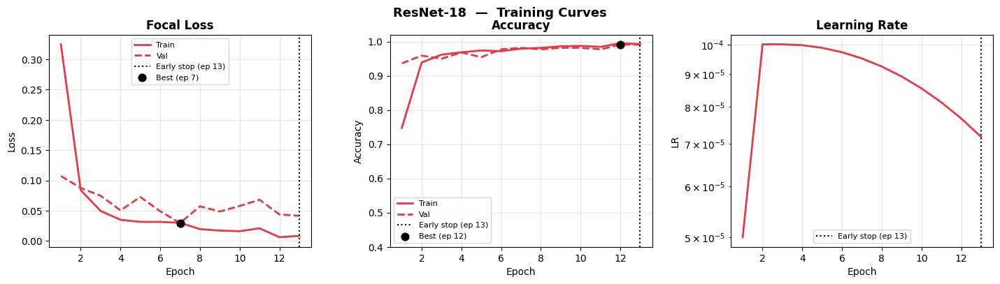

Saved: /kaggle/working/curves_SqueezeNet1_1.png  |  stopped=30  best_val_acc=0.9863


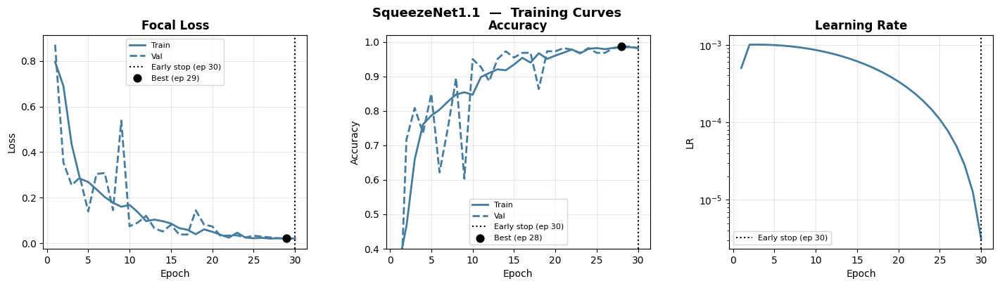

Saved: /kaggle/working/curves_EfficientNet_B0.png  |  stopped=23  best_val_acc=0.9909


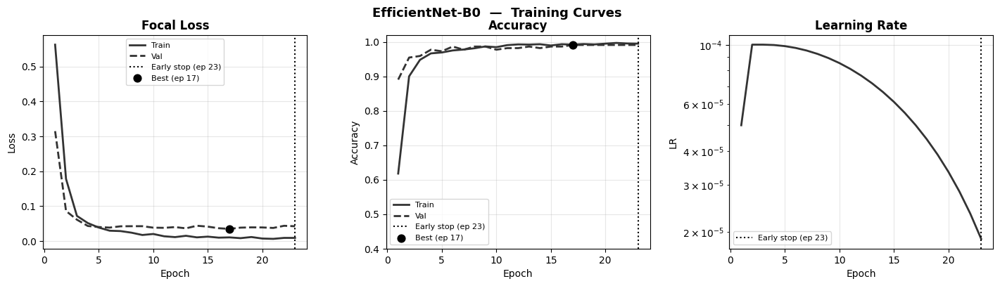

Saved: /kaggle/working/curves_ViT_Tiny.png  |  stopped=13  best_val_acc=0.9863


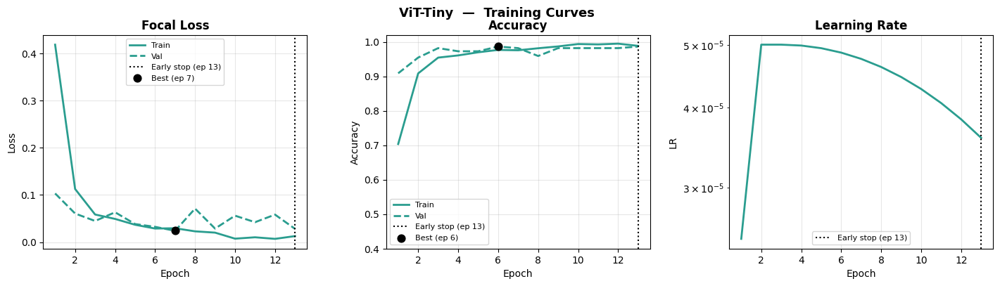

Saved: /kaggle/working/curves_DeiT_Tiny.png  |  stopped=23  best_val_acc=0.9909


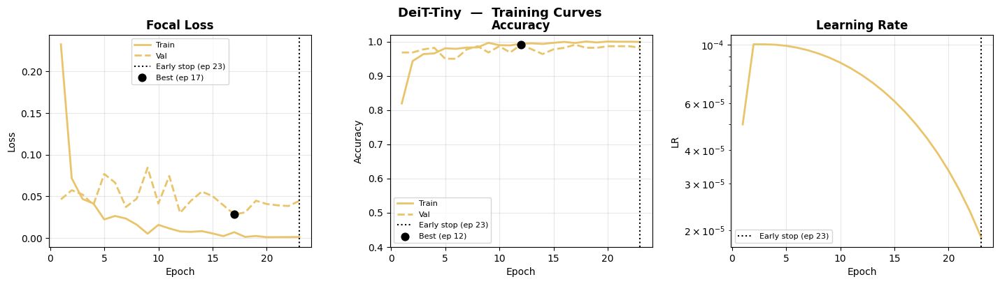

Saved: /kaggle/working/curves_AGCTNet.png  |  stopped=17  best_val_acc=0.9909


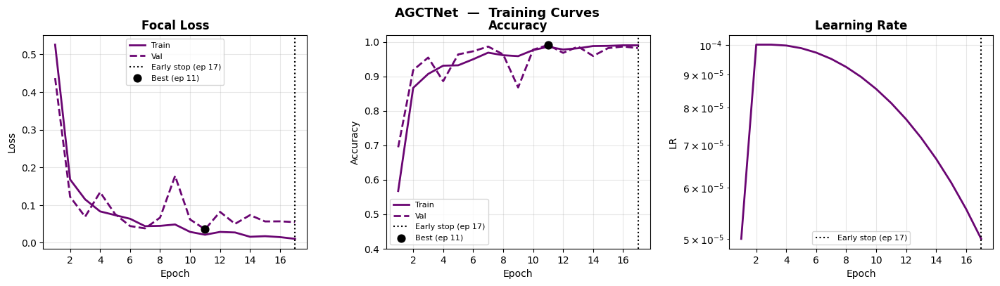

In [24]:
# ============================================================
# Block 14: Training Curves — one figure per model
# ============================================================

colors = {
    "ResNet-18":     "#E63946",
    "SqueezeNet1.1": "#457B9D",
    "ViT-Tiny":      "#2A9D8F",
    "DeiT-Tiny":     "#E9C46A",
    "AGCTNet":       "#6A0572",
}

for name, h in hist_registry.items():
    ep      = range(1, len(h["train_loss"]) + 1)
    color   = colors.get(name, "#333333")
    stopped = h.get("stopped_epoch", len(h["train_loss"]))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4),
                              facecolor="white")
    fig.suptitle(f"{name}  —  Training Curves",
                 fontsize=13, fontweight="bold")

    # ── Loss ──────────────────────────────────────────────────
    axes[0].plot(ep, h["train_loss"], color=color,
                 lw=2, label="Train")
    axes[0].plot(ep, h["val_loss"],   color=color,
                 lw=2, ls="--", label="Val")
    axes[0].axvline(stopped, color="black", lw=1.5,
                    ls=":", label=f"Early stop (ep {stopped})")
    best_ep = int(np.argmin(h["val_loss"])) + 1
    axes[0].scatter(best_ep, min(h["val_loss"]),
                    color="black", zorder=5, s=60,
                    label=f"Best (ep {best_ep})")
    axes[0].set_title("Focal Loss", fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.3)

    # ── Accuracy ──────────────────────────────────────────────
    axes[1].plot(ep, h["train_acc"], color=color,
                 lw=2, label="Train")
    axes[1].plot(ep, h["val_acc"],   color=color,
                 lw=2, ls="--", label="Val")
    axes[1].axvline(stopped, color="black", lw=1.5,
                    ls=":", label=f"Early stop (ep {stopped})")
    best_acc_ep = int(np.argmax(h["val_acc"])) + 1
    axes[1].scatter(best_acc_ep, max(h["val_acc"]),
                    color="black", zorder=5, s=60,
                    label=f"Best (ep {best_acc_ep})")
    axes[1].set_title("Accuracy", fontweight="bold")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_ylim(0.4, 1.02)
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.3)

    # ── Learning Rate ──────────────────────────────────────────
    if "lr" in h and h["lr"]:
        axes[2].plot(ep, h["lr"], color=color, lw=2)
        axes[2].axvline(stopped, color="black", lw=1.5,
                        ls=":", label=f"Early stop (ep {stopped})")
        axes[2].set_title("Learning Rate", fontweight="bold")
        axes[2].set_xlabel("Epoch")
        axes[2].set_ylabel("LR")
        axes[2].set_yscale("log")
        axes[2].legend(fontsize=8)
        axes[2].grid(alpha=0.3)
    else:
        axes[2].axis("off")

    plt.subplots_adjust(wspace=0.3, left=0.07, right=0.97,
                        top=0.88, bottom=0.12)

    save_path = (f"/kaggle/working/curves_"
                 f"{name.replace('.','_').replace('-','_')}.png")
    fig.savefig(save_path, dpi=130, bbox_inches="tight",
                facecolor="white")
    print(f"Saved: {save_path}  |  "
          f"stopped={stopped}  "
          f"best_val_acc={max(h['val_acc']):.4f}")
    ipy_display(fig)
    plt.close(fig)

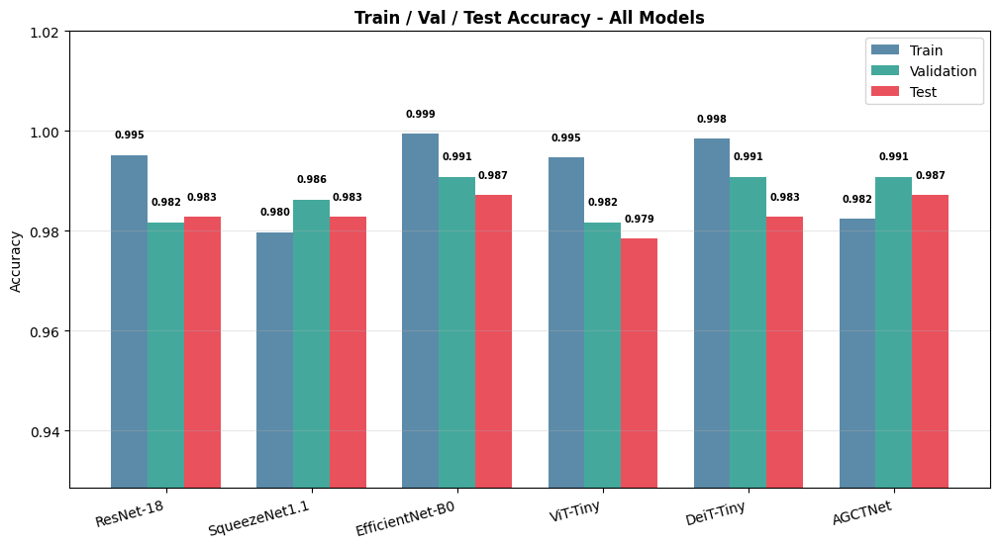

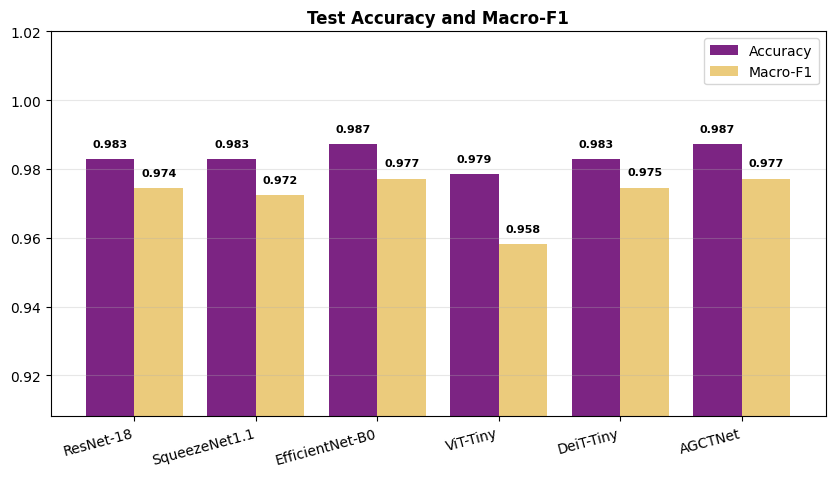

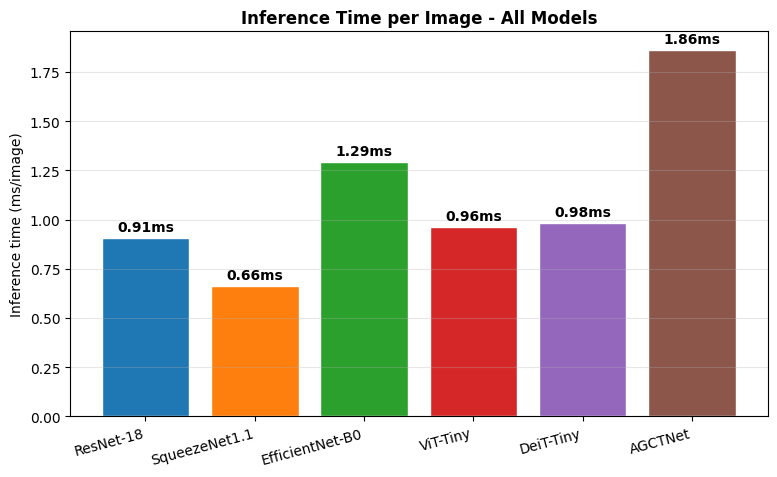

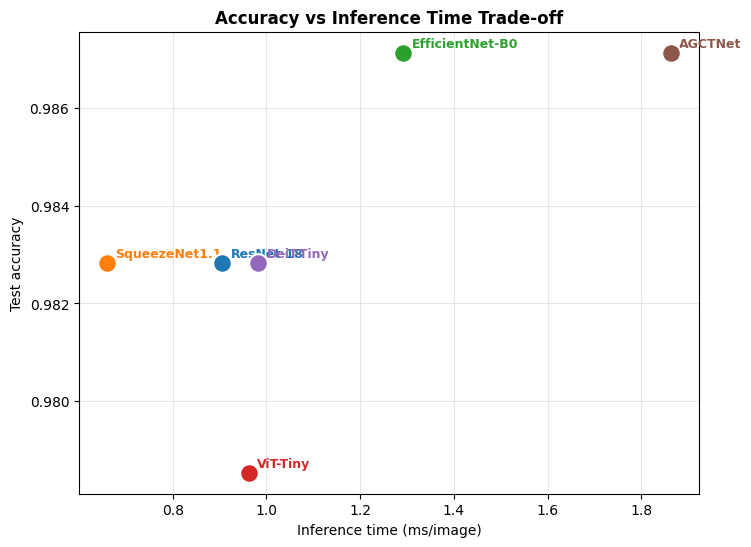

In [25]:
# ============================================================
# Block 15 (Updated): Accuracy / F1 / Inference-time charts
# Colours are generated per model, so adding or removing models
# can never raise an IndexError.
# ============================================================
model_names = list(summary.keys())
cmap       = plt.cm.tab10
bar_colors = [cmap(i % 10) for i in range(len(model_names))]

tr_accs  = [summary[n]["train_acc"] for n in model_names]
va_accs  = [summary[n]["val_acc"]   for n in model_names]
te_accs  = [summary[n]["test_acc"]  for n in model_names]
te_f1    = [summary[n]["test_f1"]   for n in model_names]
infer_ms = [summary[n]["infer_ms"]  for n in model_names]

def finish(fig, path):
    fig.savefig(path, dpi=130, bbox_inches="tight", facecolor="white")
    ipy_display(fig); plt.close(fig)

# ── Figure 1: Train / Val / Test accuracy ─────────────────────
x, w = np.arange(len(model_names)), 0.25
fig, ax = plt.subplots(figsize=(12, 6), facecolor="white")
for off, vals, lab, col in [(-w, tr_accs, "Train", "#457B9D"),
                            (0,  va_accs, "Validation", "#2A9D8F"),
                            (w,  te_accs, "Test", "#E63946")]:
    bars = ax.bar(x + off, vals, w, label=lab, color=col, alpha=0.88)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.003,
                f"{b.get_height():.3f}", ha="center", va="bottom", fontsize=7, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(model_names, rotation=15, ha="right")
ax.set_ylabel("Accuracy")
ax.set_ylim(min(tr_accs + va_accs + te_accs) - 0.05, 1.02)
ax.set_title("Train / Val / Test Accuracy - All Models", fontweight="bold")
ax.legend(); ax.grid(axis="y", alpha=0.3)
finish(fig, f"{WORK_DIR}/accuracy_comparison.png")

# ── Figure 2: Test accuracy vs test macro-F1 ──────────────────
fig, ax = plt.subplots(figsize=(10, 5), facecolor="white")
b1 = ax.bar(x - 0.2, te_accs, 0.4, label="Accuracy", color="#6A0572", alpha=0.88)
b2 = ax.bar(x + 0.2, te_f1,   0.4, label="Macro-F1", color="#E9C46A", alpha=0.88)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.003,
                f"{b.get_height():.3f}", ha="center", va="bottom", fontsize=8, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(model_names, rotation=15, ha="right")
ax.set_ylim(min(te_accs + te_f1) - 0.05, 1.02)
ax.set_title("Test Accuracy and Macro-F1", fontweight="bold")
ax.legend(); ax.grid(axis="y", alpha=0.3)
finish(fig, f"{WORK_DIR}/test_accuracy_f1.png")

# ── Figure 3: Inference time ──────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5), facecolor="white")
bars = ax.bar(model_names, infer_ms, color=bar_colors, edgecolor="white")
for b, ms in zip(bars, infer_ms):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02,
            f"{ms:.2f}ms", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_xticks(range(len(model_names))); ax.set_xticklabels(model_names, rotation=15, ha="right")
ax.set_ylabel("Inference time (ms/image)")
ax.set_title("Inference Time per Image - All Models", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
finish(fig, f"{WORK_DIR}/inference_time.png")

# ── Figure 4: Accuracy vs inference time ──────────────────────
fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")
for i, name in enumerate(model_names):
    ax.scatter(infer_ms[i], te_accs[i], color=bar_colors[i], s=180, zorder=5,
               edgecolors="white", linewidths=1.5)
    ax.annotate(name, (infer_ms[i], te_accs[i]), xytext=(6, 4), textcoords="offset points",
                fontsize=9, fontweight="bold", color=bar_colors[i])
ax.set_xlabel("Inference time (ms/image)"); ax.set_ylabel("Test accuracy")
ax.set_title("Accuracy vs Inference Time Trade-off", fontweight="bold"); ax.grid(alpha=0.3)
finish(fig, f"{WORK_DIR}/acc_vs_infer.png")


ResNet-18 | Test Acc 0.9828 | F1 0.9745
[[89  0  0  0]
 [ 0 35  2  0]
 [ 1  0 95  0]
 [ 1  0  0 10]]


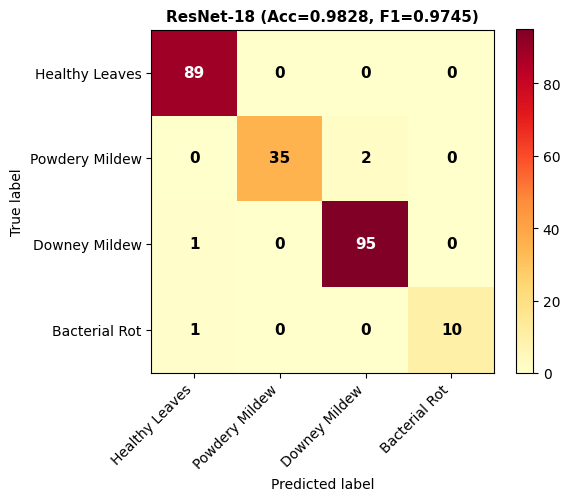


SqueezeNet1.1 | Test Acc 0.9828 | F1 0.9724
[[88  1  0  0]
 [ 0 35  2  0]
 [ 0  0 96  0]
 [ 1  0  0 10]]


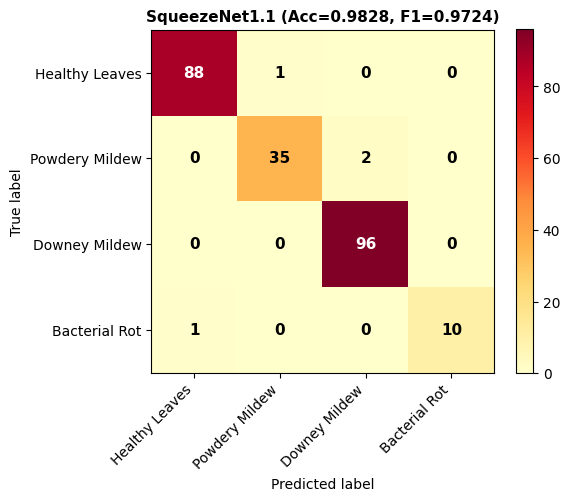


EfficientNet-B0 | Test Acc 0.9871 | F1 0.9772
[[89  0  0  0]
 [ 0 35  2  0]
 [ 0  0 96  0]
 [ 1  0  0 10]]


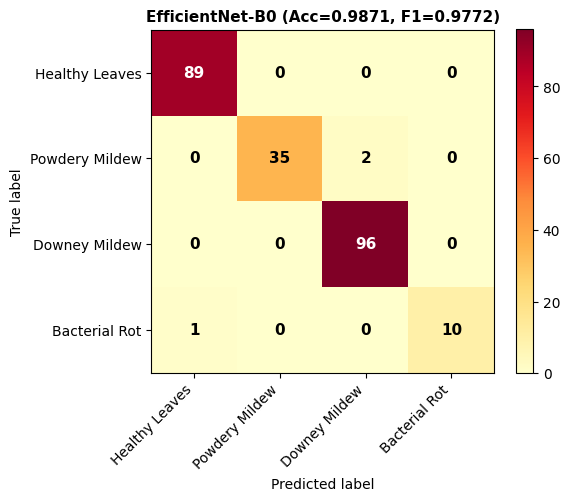


ViT-Tiny | Test Acc 0.9785 | F1 0.9581
[[89  0  0  0]
 [ 0 34  3  0]
 [ 0  0 96  0]
 [ 0  0  2  9]]


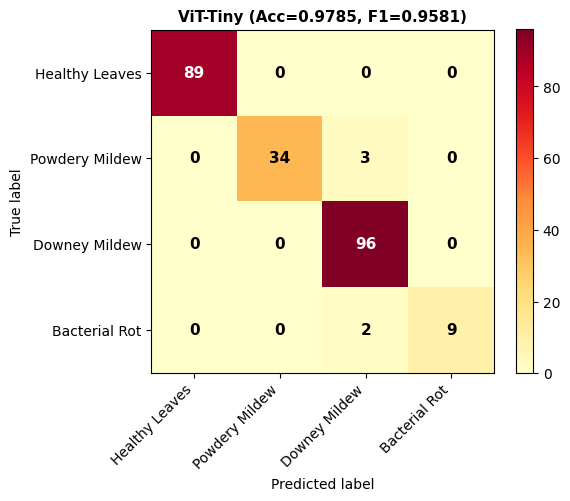


DeiT-Tiny | Test Acc 0.9828 | F1 0.9746
[[89  0  0  0]
 [ 0 35  2  0]
 [ 1  0 95  0]
 [ 0  0  1 10]]


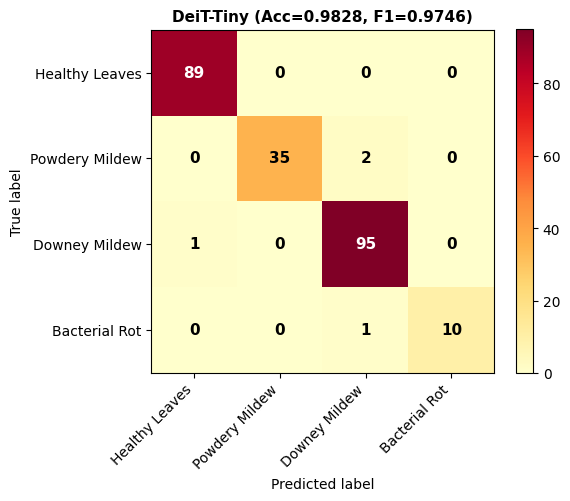


AGCTNet | Test Acc 0.9871 | F1 0.9772
[[88  1  0  0]
 [ 0 36  1  0]
 [ 0  0 96  0]
 [ 1  0  0 10]]


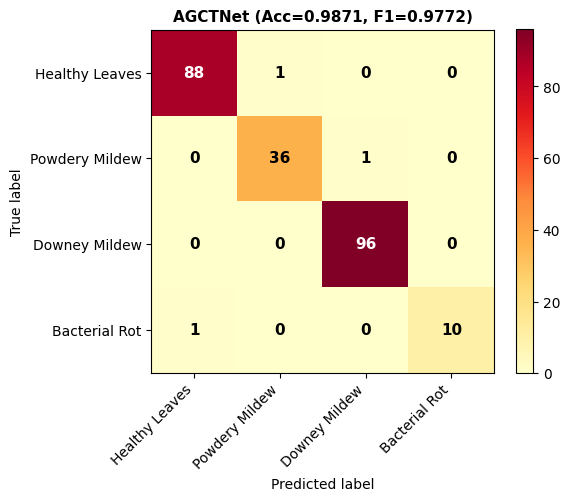

In [26]:
# ============================================================
# Block 16: Confusion Matrices - All Models
# ============================================================
def plot_cm(cm, class_names, title, save_path=None):
    fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")
    im = ax.imshow(cm, interpolation="nearest", cmap="YlOrRd")
    plt.colorbar(im, ax=ax)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ticks = np.arange(len(class_names))
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.set_xticklabels(class_names, rotation=45, ha="right"); ax.set_yticklabels(class_names)
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=11, fontweight="bold",
                    color="white" if cm[i, j] > thresh else "black")
    ax.set_ylabel("True label"); ax.set_xlabel("Predicted label")
    plt.tight_layout()
    if save_path: fig.savefig(save_path, dpi=130, bbox_inches="tight", facecolor="white")
    ipy_display(fig); plt.close(fig)

for name in model_names:
    yt, yp = summary[name]["y_true_test"], summary[name]["y_pred_test"]
    cm = confusion_matrix(yt, yp, labels=range(num_classes))
    print(f"\n{name} | Test Acc {summary[name]['test_acc']:.4f} | F1 {summary[name]['test_f1']:.4f}")
    print(cm)
    plot_cm(cm, classes,
            f"{name} (Acc={summary[name]['test_acc']:.4f}, F1={summary[name]['test_f1']:.4f})",
            f"{WORK_DIR}/cm_{safe(name)}.png")

In [27]:
# ============================================================
# Block 17: Classification Reports - All Models
# ============================================================
all_rows = []
for name in model_names:
    yt, yp = summary[name]["y_true_test"], summary[name]["y_pred_test"]
    print(f"\n{'='*60}\n  {name} | {summary[name]['infer_ms']:.2f} ms/img\n{'='*60}")
    print(classification_report(yt, yp, labels=range(num_classes), target_names=classes, zero_division=0))
    rd = classification_report(yt, yp, labels=range(num_classes), target_names=classes,
                               output_dict=True, zero_division=0)
    for cls in classes:
        r = rd[cls]
        all_rows.append({"Model": name, "Class": cls, "Precision": round(r["precision"], 4),
                         "Recall": round(r["recall"], 4), "F1-score": round(r["f1-score"], 4),
                         "Support": int(r["support"])})
df_reports = pd.DataFrame(all_rows)
df_reports.to_csv(f"{WORK_DIR}/per_class_metrics.csv", index=False)
print("\nSaved: per_class_metrics.csv")


  ResNet-18 | 0.91 ms/img
                precision    recall  f1-score   support

Healthy Leaves       0.98      1.00      0.99        89
Powdery Mildew       1.00      0.95      0.97        37
 Downey Mildew       0.98      0.99      0.98        96
 Bacterial Rot       1.00      0.91      0.95        11

      accuracy                           0.98       233
     macro avg       0.99      0.96      0.97       233
  weighted avg       0.98      0.98      0.98       233


  SqueezeNet1.1 | 0.66 ms/img
                precision    recall  f1-score   support

Healthy Leaves       0.99      0.99      0.99        89
Powdery Mildew       0.97      0.95      0.96        37
 Downey Mildew       0.98      1.00      0.99        96
 Bacterial Rot       1.00      0.91      0.95        11

      accuracy                           0.98       233
     macro avg       0.99      0.96      0.97       233
  weighted avg       0.98      0.98      0.98       233


  EfficientNet-B0 | 1.29 ms/img
       

In [28]:
# ============================================================
# Block 18: Sensitivity / Specificity / PPV / NPV + bootstrap 95% CI
# ============================================================
def per_class_metrics(y_true, y_pred, class_names):
    cm  = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
    out = {}
    for i, cls in enumerate(class_names):
        TP = cm[i, i]; FN = cm[i, :].sum() - TP; FP = cm[:, i].sum() - TP
        TN = cm.sum() - TP - FP - FN
        out[cls] = {"Sensitivity": TP / (TP + FN + 1e-8), "Specificity": TN / (TN + FP + 1e-8),
                    "PPV": TP / (TP + FP + 1e-8),         "NPV": TN / (TN + FN + 1e-8)}
    return out, cm

def bootstrap_ci(y_true, y_pred, B=2000, conf=0.95, seed=42, metric="acc"):
    rng, n, vals = np.random.default_rng(seed), len(y_true), []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        vals.append(accuracy_score(y_true[idx], y_pred[idx]) if metric == "acc"
                    else f1_score(y_true[idx], y_pred[idx], average="macro"))
    return np.percentile(vals, (1 - conf) / 2 * 100), np.percentile(vals, (1 + conf) / 2 * 100)

adv_rows = []
for name in model_names:
    yt, yp = summary[name]["y_true_test"], summary[name]["y_pred_test"]
    pcm, _ = per_class_metrics(yt, yp, classes)
    lo, hi   = bootstrap_ci(yt, yp)
    flo, fhi = bootstrap_ci(yt, yp, metric="f1")
    macro = {k: np.mean([pcm[c][k] for c in classes]) for k in ["Sensitivity", "Specificity", "PPV", "NPV"]}
    print(f"\n{'='*55}\n  {name}\n  Test Acc : {summary[name]['test_acc']:.4f}  95% CI [{lo:.4f}, {hi:.4f}]"
          f"\n  Macro-F1 : {summary[name]['test_f1']:.4f}  95% CI [{flo:.4f}, {fhi:.4f}]")
    for k, v in macro.items(): print(f"  Macro {k:12s}: {v:.4f}")
    adv_rows.append({"Model": name, "Test_Acc": round(summary[name]["test_acc"], 4),
                     "CI_low": round(lo, 4), "CI_high": round(hi, 4),
                     "Macro_F1": round(summary[name]["test_f1"], 4),
                     "F1_CI_low": round(flo, 4), "F1_CI_high": round(fhi, 4),
                     "Infer_ms": round(summary[name]["infer_ms"], 4),
                     **{f"Macro_{k}": round(v, 4) for k, v in macro.items()}})
df_adv = pd.DataFrame(adv_rows).sort_values("Test_Acc", ascending=False).reset_index(drop=True)
df_adv.to_csv(f"{WORK_DIR}/advanced_metrics.csv", index=False)
print("\n=== Advanced Metrics Summary ===")
print(df_adv.to_string(index=False))


  ResNet-18
  Test Acc : 0.9828  95% CI [0.9657, 0.9957]
  Macro-F1 : 0.9745  95% CI [0.9370, 0.9973]
  Macro Sensitivity : 0.9612
  Macro Specificity : 0.9929
  Macro PPV         : 0.9894
  Macro NPV         : 0.9945

  SqueezeNet1.1
  Test Acc : 0.9828  95% CI [0.9614, 0.9957]
  Macro-F1 : 0.9724  95% CI [0.9344, 0.9958]
  Macro Sensitivity : 0.9610
  Macro Specificity : 0.9933
  Macro PPV         : 0.9851
  Macro NPV         : 0.9946

  EfficientNet-B0
  Test Acc : 0.9871  95% CI [0.9700, 1.0000]
  Macro-F1 : 0.9772  95% CI [0.9405, 1.0000]
  Macro Sensitivity : 0.9638
  Macro Specificity : 0.9946
  Macro PPV         : 0.9921
  Macro NPV         : 0.9964

  ViT-Tiny
  Test Acc : 0.9785  95% CI [0.9571, 0.9957]
  Macro-F1 : 0.9581  95% CI [0.9042, 0.9916]
  Macro Sensitivity : 0.9343
  Macro Specificity : 0.9909
  Macro PPV         : 0.9876
  Macro NPV         : 0.9940

  DeiT-Tiny
  Test Acc : 0.9828  95% CI [0.9657, 0.9957]
  Macro-F1 : 0.9746  95% CI [0.9373, 0.9973]
  Macro Sens

In [29]:
# ============================================================
# Block 19 (Updated): McNemar tests + Holm correction
# AGCTNet is compared with every baseline, so the raw p-values are
# adjusted for multiple comparisons (Holm).
# ============================================================
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

def run_mcnemar(y_true, pred_a, pred_b):
    a_right, b_right = (pred_a == y_true), (pred_b == y_true)
    b = int((~a_right &  b_right).sum())      # only B correct
    c = int(( a_right & ~b_right).sum())      # only A correct
    p = mcnemar([[0, b], [c, 0]], exact=(b + c) < 25).pvalue
    return b, c, p

y_true_ref  = summary["AGCTNet"]["y_true_test"]
y_pred_agct = summary["AGCTNet"]["y_pred_test"]

rows = []
for name in model_names:
    if name == "AGCTNet": continue
    b, c, p = run_mcnemar(y_true_ref, summary[name]["y_pred_test"], y_pred_agct)
    rows.append({"Baseline": name, "only_AGCTNet_correct": b, "only_baseline_correct": c, "p_raw": p})

df_mc = pd.DataFrame(rows)
df_mc["p_holm"]      = multipletests(df_mc.p_raw, method="holm")[1]
df_mc["significant"] = df_mc.p_holm < 0.05
df_mc = df_mc.round(4)
df_mc.to_csv(f"{WORK_DIR}/mcnemar_agctnet_vs_baselines.csv", index=False)
print("=== McNemar: AGCTNet vs each baseline (Holm-corrected) ===\n")
print(df_mc.to_string(index=False))

# ── CNN vs Transformer pairwise (exploratory, uncorrected) ────
print("\n=== CNN vs Transformer (exploratory) ===")
for a, b_ in [("ResNet-18", "ViT-Tiny"), ("SqueezeNet1.1", "DeiT-Tiny")]:
    nb, nc, p = run_mcnemar(y_true_ref, summary[a]["y_pred_test"], summary[b_]["y_pred_test"])
    print(f"  {a:<16} vs {b_:<10} b={nb:3d} c={nc:3d} p={p:.4f}")

=== McNemar: AGCTNet vs each baseline (Holm-corrected) ===

       Baseline  only_AGCTNet_correct  only_baseline_correct  p_raw  p_holm  significant
      ResNet-18                     2                      1  1.000     1.0        False
  SqueezeNet1.1                     2                      1  1.000     1.0        False
EfficientNet-B0                     1                      1  1.000     1.0        False
       ViT-Tiny                     3                      1  0.625     1.0        False
      DeiT-Tiny                     2                      1  1.000     1.0        False

=== CNN vs Transformer (exploratory) ===
  ResNet-18        vs ViT-Tiny   b=  1 c=  2 p=1.0000
  SqueezeNet1.1    vs DeiT-Tiny  b=  1 c=  1 p=1.0000


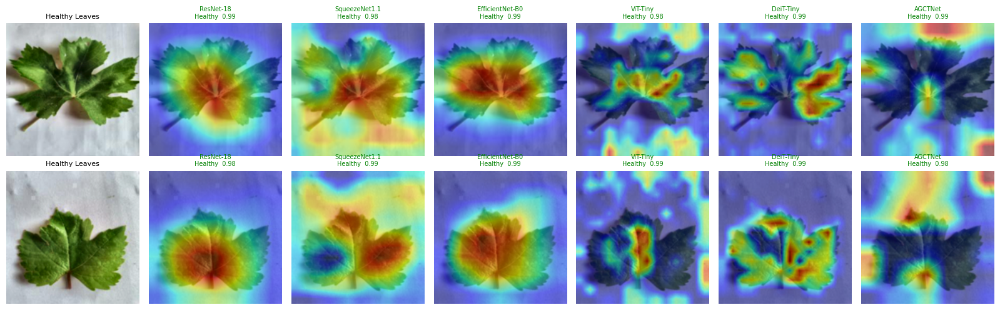

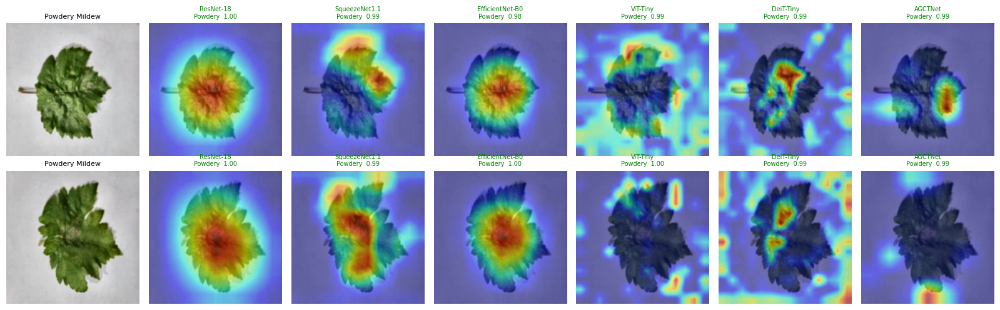

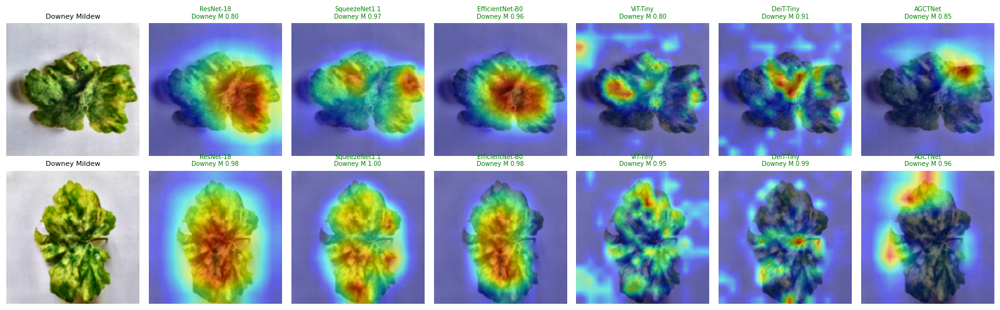

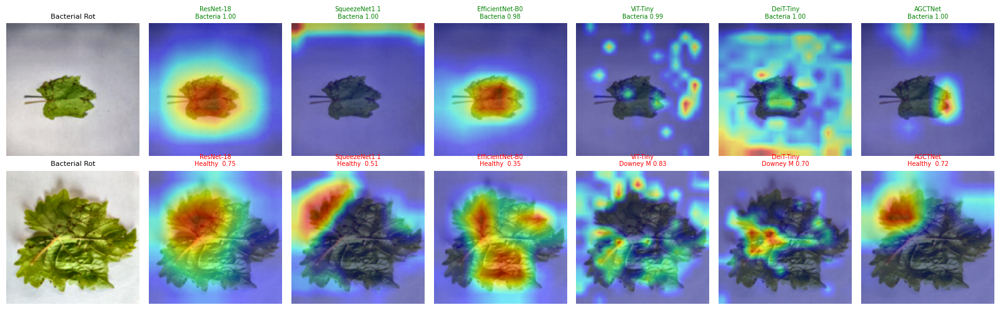

Grad-CAM produced for every model: {'ResNet-18': True, 'SqueezeNet1.1': True, 'EfficientNet-B0': True, 'ViT-Tiny': True, 'DeiT-Tiny': True, 'AGCTNet': True}

           Model  AUC_del_CAM  AUC_del_random  Gap(random-CAM)
      ResNet-18       0.2984          0.1935          -0.1049
  SqueezeNet1.1       0.2594          0.2019          -0.0575
EfficientNet-B0       0.3106          0.1799          -0.1307
       ViT-Tiny       0.3352          0.3833           0.0481
      DeiT-Tiny       0.4238          0.4452           0.0215
        AGCTNet       0.4214          0.1613          -0.2602

Positive gap = the highlighted pixels really drive the prediction.
NGLD has no lesion masks: for the claim 'heatmaps cover disease regions' also have a plant-pathology
expert rate the saved gradcam_*.png grids (e.g. 20 images/class) and report that hit-rate.


In [30]:
# ============================================================
# Block 20 (REPLACES old Block 20): Grad-CAM, fixed + verified
# Root causes of the old errors:
#  * ResNet: backbone was frozen and the input had no grad -> no graph
#    -> backward hook never fired -> CAM = None.
#  * SqueezeNet: full_backward_hook + in-place ReLU in Fire modules.
#  * ViT/DeiT: (B,197,C) tokens were averaged over the wrong axes.
# Fix: forward hook + torch.autograd.grad (no backward hooks), input
# requires_grad, in-place ops disabled, proper ViT token reshape.
# ============================================================
class GradCAM:
    def __init__(self, model, layer, reshape=None):
        self.model, self.reshape, self.acts = model, reshape, None
        self._h = layer.register_forward_hook(lambda m, i, o: setattr(self, "acts", o))
    def __call__(self, x, class_idx=None):
        self.model.eval()
        x = x.detach().clone().requires_grad_(True)
        with torch.enable_grad():
            logits = self.model(x)
            if class_idx is None: class_idx = int(logits.argmax(1)[0])
            grads = torch.autograd.grad(logits[0, class_idx], self.acts)[0]
        a, g = self.acts, grads
        if self.reshape: a, g = self.reshape(a), self.reshape(g)
        cam = F.relu((g.mean((2, 3), keepdim=True) * a).sum(1))[0].detach()
        cam = cam - cam.min(); cam = cam / (cam.max() + 1e-8)
        return cam.cpu().numpy(), class_idx, F.softmax(logits, 1)[0].detach().cpu().numpy()
    def remove(self): self._h.remove()

def vit_reshape(m):
    npfx, (gh, gw) = getattr(m, "num_prefix_tokens", 1), m.patch_embed.grid_size
    def f(t):                                   # (B, prefix+N, C) -> (B, C, gh, gw)
        t = t[:, npfx:, :]
        return t.reshape(t.size(0), gh, gw, t.size(2)).permute(0, 3, 1, 2)
    return f

def gradcam_target(name, m):
    if name == "ResNet-18":                          return m.layer4[-1], None
    if name in ("SqueezeNet1.1", "EfficientNet-B0"): return m.features[-1], None
    if name in ("ViT-Tiny", "DeiT-Tiny"):            return m.blocks[-1].norm1, vit_reshape(m)
    if name == "AGCTNet":                            return m.cag, None      # fused 7x7 map
    raise KeyError(name)

def to_tensor(path): return val_test_tf(Image.open(path).convert("RGB")).unsqueeze(0).to(device)
def overlay(path, cam, a=0.5):
    img = np.array(Image.open(path).convert("RGB").resize((224, 224))) / 255.0
    up  = cv2.resize(cam, (224, 224), interpolation=cv2.INTER_LINEAR)
    return np.clip((1 - a) * img + a * plt.cm.jet(up)[..., :3], 0, 1)

# ── 1. Visual grids: one figure per class, columns = models ─────
N_VIS = 2
cam_ok = {nm: True for nm in model_registry}
for ci, cls in enumerate(classes):
    paths = test_df[test_df.label == ci].path.tolist()[:N_VIS]
    fig, axes = plt.subplots(len(paths), 1 + len(model_registry),
                             figsize=(2.3 * (1 + len(model_registry)), 2.5 * len(paths)),
                             facecolor="white", squeeze=False)
    for r, p in enumerate(paths):
        axes[r, 0].imshow(Image.open(p).convert("RGB").resize((224, 224)))
        axes[r, 0].set_title(f"{cls}", fontsize=8); axes[r, 0].axis("off")
        x = to_tensor(p)
        for c, (nm, mdl) in enumerate(model_registry.items(), start=1):
            layer, rs = gradcam_target(nm, mdl); g = GradCAM(mdl, layer, rs)
            try:
                cam, pi, pr = g(x)
                axes[r, c].imshow(overlay(p, cam))
                axes[r, c].set_title(f"{nm}\n{classes[pi][:8]} {pr[pi]:.2f}", fontsize=7,
                                     color="green" if pi == ci else "red")
            except Exception as e:
                cam_ok[nm] = False; axes[r, c].set_title(f"{nm}\nERROR", fontsize=7, color="red"); print(nm, "->", e)
            finally: g.remove()
            axes[r, c].axis("off")
    plt.tight_layout()
    fig.savefig(f"{WORK_DIR}/gradcam_{safe(cls)}.png", dpi=130, bbox_inches="tight", facecolor="white")
    ipy_display(fig); plt.close(fig)
print("Grad-CAM produced for every model:", cam_ok)

# ── 2. Quantitative faithfulness (deletion test) ─────────────────
# Remove the most-salient pixels first (set to dataset mean). If the CAM
# is meaningful, the predicted-class probability must fall much faster
# than when random pixels are removed. Lower AUC = better.
FRACS = [0, .05, .1, .2, .3, .5]
def _auc(y): return float(sum((FRACS[i+1]-FRACS[i]) * (y[i]+y[i+1]) / 2 for i in range(len(FRACS)-1)))
@torch.no_grad()
def del_curve(model, x, order, cls_idx):
    xs = []
    for f in FRACS:
        mask = np.ones(order.size, np.float32); mask[order[:int(f * order.size)]] = 0
        xs.append(x * torch.from_numpy(mask.reshape(1, 1, 224, 224)).to(device))
    return F.softmax(model(torch.cat(xs)), 1)[:, cls_idx].cpu().numpy()

N_PER_CLASS, rng = 15, np.random.default_rng(SEED)
rows = []
for nm, mdl in model_registry.items():
    layer, rs = gradcam_target(nm, mdl); g = GradCAM(mdl, layer, rs)
    a_cam, a_rnd = [], []
    for ci in range(num_classes):
        for p in test_df[test_df.label == ci].path.tolist()[:N_PER_CLASS]:
            x = to_tensor(p); cam, pi, _ = g(x)
            order = np.argsort(-cv2.resize(cam, (224, 224)).ravel())
            a_cam.append(_auc(del_curve(mdl, x, order, pi)))
            a_rnd.append(np.mean([_auc(del_curve(mdl, x, rng.permutation(order.size), pi)) for _ in range(2)]))
    g.remove()
    rows.append({"Model": nm, "AUC_del_CAM": np.mean(a_cam), "AUC_del_random": np.mean(a_rnd),
                 "Gap(random-CAM)": np.mean(a_rnd) - np.mean(a_cam)})
df_cam = pd.DataFrame(rows).round(4); df_cam.to_csv(f"{WORK_DIR}/gradcam_faithfulness.csv", index=False)
print("\n", df_cam.to_string(index=False))
print("\nPositive gap = the highlighted pixels really drive the prediction.")
print("NGLD has no lesion masks: for the claim 'heatmaps cover disease regions' also have a plant-pathology")
print("expert rate the saved gradcam_*.png grids (e.g. 20 images/class) and report that hit-rate.")

In [ ]:
# ============================================================
# Block 12b (REPLACES old ablation cell): same protocol, same split
# Variants are built from the single AGCTNet class via flags.
# Uses AGCTNet's tuned LR for all variants; F reuses the main run.
# ============================================================
CE_criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
ABL = {"A: CNN branch only":          (dict(use_deit=False), criterion),
       "B: DeiT branch only":         (dict(use_cnn=False),  criterion),
       "C: Dual branch, no CAG":      (dict(use_cag=False),  criterion),
       "D: Dual+CAG, no Transformer": (dict(use_transformer=False), criterion),
       "E: Full AGCTNet, CE loss":    (dict(),               CE_criterion)}
rows = []
for variant, (kw, crit_) in ABL.items():
    m = build_model("AGCTNet", **kw)
    m, h, _ = train_model(m, f"abl_{variant[0]}", train_loader, val_loader, crit_,
                          num_epochs=TUNE_EPOCHS, patience=TUNE_PATIENCE, lr=best_lr["AGCTNet"])
    te = predict(m, test_loader, device); va = predict(m, val_loader, device)
    rows.append({"Variant": variant, "Val_F1": f1_score(va["y_true"], va["y_pred"], average="macro"),
                 "Test_Acc": accuracy_score(te["y_true"], te["y_pred"]),
                 "Test_F1": f1_score(te["y_true"], te["y_pred"], average="macro"),
                 "Infer_ms": te["ms_per_img"], "Params_M": sum(p.numel() for p in m.parameters()) / 1e6})
    del m; torch.cuda.empty_cache()
s = summary["AGCTNet"]
rows.append({"Variant": "F: Full AGCTNet, Focal loss (proposed)", "Val_F1": s["val_f1"], "Test_Acc": s["test_acc"],
             "Test_F1": s["test_f1"], "Infer_ms": s["infer_ms"], "Params_M": s["params_M"]})
df_abl = pd.DataFrame(rows).round(4); df_abl.to_csv(f"{WORK_DIR}/ablation_results.csv", index=False)
ablation_results = dict(zip(df_abl.Variant, df_abl.Test_Acc))
print(df_abl.to_string(index=False))
print("\nSingle seed: differences below the bootstrap CI width (Block 18) are not evidence of a real effect.")

fig, ax = plt.subplots(figsize=(11, 4.5), facecolor="white")
ax.bar(df_abl.Variant.str[:1], df_abl.Test_F1, color="#6A0572", alpha=.85)
for i, v in enumerate(df_abl.Test_F1): ax.text(i, v + .002, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylim(max(0, df_abl.Test_F1.min() - .05), 1.01); ax.set_ylabel("Test macro-F1"); ax.grid(axis="y", alpha=.3)
ax.set_title("Ablation (group-aware split, equal training protocol)", fontweight="bold")
fig.savefig(f"{WORK_DIR}/ablation_f1.png", dpi=130, bbox_inches="tight"); ipy_display(fig); plt.close(fig)

In [31]:
# ============================================================
# Block 21 (REPLACES old CV): 5-fold CV INSIDE the development set only
# - test split is excluded -> remains an untouched final holdout
# - StratifiedGroupKFold: near-duplicates never straddle folds
# - early stopping uses an inner validation split taken from the fold's
#   training data, so the fold's held-out part is only scored, never used
#   for model selection
# - same protocol & tuned LR for every model in CV_MODELS
# ============================================================
CV_MODELS  = list(MODEL_BUILDERS)           # e.g. ["AGCTNet", "ResNet-18"] to save time
CV_EPOCHS, CV_PATIENCE, K = 20, 5, 5
dev_df = split_df[split_df.split.isin(["train", "val"])].reset_index(drop=True)
assert set(dev_df.group).isdisjoint(set(test_df.group)), "test groups leaked into CV"
print(f"CV on {len(dev_df)} development images; {len(test_df)} test images stay untouched.\n")

CVLOG = f"{WORK_DIR}/cv_log.json"
cvlog = json.load(open(CVLOG)) if os.path.exists(CVLOG) else {}
outer = StratifiedGroupKFold(n_splits=K, shuffle=True, random_state=SEED)
for fold, (tr_i, ho_i) in enumerate(outer.split(dev_df, dev_df.label, dev_df.group), start=1):
    sub = dev_df.iloc[tr_i].reset_index(drop=True)
    itr, iva = next(StratifiedGroupKFold(9, shuffle=True, random_state=SEED + fold).split(sub, sub.label, sub.group))
    L = make_loaders(samples_of(sub.iloc[itr]), samples_of(sub.iloc[iva]), samples_of(dev_df.iloc[ho_i]))
    for name in CV_MODELS:
        key = f"{name}|{fold}"
        if key in cvlog: print("skip", key); continue
        m = build_model(name)
        m, _, _ = train_model(m, f"cv_{safe(name)}_f{fold}", L["train"], L["val"], criterion,
                              num_epochs=CV_EPOCHS, patience=CV_PATIENCE, lr=best_lr[name], verbose=False)
        r = predict(m, L["test"], device)
        cvlog[key] = {"Model": name, "Fold": fold, "Acc": accuracy_score(r["y_true"], r["y_pred"]),
                      "MacroF1": f1_score(r["y_true"], r["y_pred"], average="macro"),
                      "BalAcc": balanced_accuracy_score(r["y_true"], r["y_pred"])}
        json.dump(cvlog, open(CVLOG, "w"))
        print(f"fold {fold} {name:16s} acc={cvlog[key]['Acc']:.4f}  F1={cvlog[key]['MacroF1']:.4f}")
        del m; torch.cuda.empty_cache()

df_cv = pd.DataFrame(cvlog.values()); df_cv.to_csv(f"{WORK_DIR}/cv_fold_results.csv", index=False)
cv_sum = df_cv.groupby("Model").agg(Acc_mean=("Acc", "mean"), Acc_std=("Acc", "std"),
                                    F1_mean=("MacroF1", "mean"), F1_std=("MacroF1", "std"),
                                    BalAcc_mean=("BalAcc", "mean")).round(4).sort_values("F1_mean", ascending=False)
cv_sum.to_csv(f"{WORK_DIR}/cv_summary.csv")
print("\n", cv_sum.to_string())
fold_accs = df_cv[df_cv.Model == "AGCTNet"].sort_values("Fold").Acc.values if "AGCTNet" in df_cv.Model.values else []
np.save(f"{WORK_DIR}/cv_fold_accuracies.npy", np.array(fold_accs))

CV on 2097 development images; 233 test images stay untouched.

fold 1 ResNet-18        acc=0.9832  F1=0.9682
fold 1 SqueezeNet1.1    acc=0.9760  F1=0.9523
fold 1 EfficientNet-B0  acc=0.9784  F1=0.9630
fold 1 ViT-Tiny         acc=0.9591  F1=0.9367
fold 1 DeiT-Tiny        acc=0.9784  F1=0.9532
fold 1 AGCTNet          acc=0.9736  F1=0.9656
fold 2 ResNet-18        acc=0.9785  F1=0.9722
fold 2 SqueezeNet1.1    acc=0.9403  F1=0.9095
fold 2 EfficientNet-B0  acc=0.9881  F1=0.9836
fold 2 ViT-Tiny         acc=0.9475  F1=0.9205
fold 2 DeiT-Tiny        acc=0.9714  F1=0.9520
fold 2 AGCTNet          acc=0.9809  F1=0.9639
fold 3 ResNet-18        acc=0.9833  F1=0.9562
fold 3 SqueezeNet1.1    acc=0.9593  F1=0.9489
fold 3 EfficientNet-B0  acc=0.9713  F1=0.9490
fold 3 ViT-Tiny         acc=0.9641  F1=0.9610
fold 3 DeiT-Tiny        acc=0.9522  F1=0.9555
fold 3 AGCTNet          acc=0.9498  F1=0.9462
fold 4 ResNet-18        acc=0.9905  F1=0.9846
fold 4 SqueezeNet1.1    acc=0.9141  F1=0.8605
fold 4 Efficient

In [36]:
# ============================================================
# Block 21b (Updated): Save everything for the application step
# ============================================================
weight_map = {n: os.path.basename(best_run[n]) for n in best_run}
cfg = {"classes": classes, "img_size": 224, "mean": IMNET_MEAN, "std": IMNET_STD,
       "weights_dir": CKPT_DIR, "weights": weight_map, "best_lr": best_lr,
       "gradcam_layers": {"ResNet-18": "layer4[-1]", "SqueezeNet1.1": "features[-1]",
                          "EfficientNet-B0": "features[-1]", "ViT-Tiny": "blocks[-1].norm1",
                          "DeiT-Tiny": "blocks[-1].norm1", "AGCTNet": "cag"},
       "preprocessing": "resize 224 -> LAB CLAHE(clip=2,tile=8x8) on L -> GaussianBlur(3,3) on L -> RGB"}
json.dump(cfg, open(f"{WORK_DIR}/inference_config.json", "w"), indent=2)
json.dump(classes, open(f"{WORK_DIR}/classes.json", "w"))
json.dump(weight_map, open(f"{WORK_DIR}/weight_files.json", "w"), indent=2)

for nm in model_names:
    np.save(f"{WORK_DIR}/{safe(nm)}_y_true.npy", summary[nm]["y_true_test"])
    np.save(f"{WORK_DIR}/{safe(nm)}_y_pred.npy", summary[nm]["y_pred_test"])
df_acc = pd.DataFrame([{"Model": n, "LR": summary[n]["lr"], "Train_Acc": summary[n]["train_acc"],
    "Val_Acc": summary[n]["val_acc"], "Test_Acc": summary[n]["test_acc"], "Test_F1": summary[n]["test_f1"],
    "Test_BalAcc": summary[n]["test_bal_acc"], "Test_Acc_Dedup": summary[n]["test_acc_dedup"],
    "Infer_ms": summary[n]["infer_ms"], "Params_M": summary[n]["params_M"]} for n in model_names]).round(4)
df_acc.to_csv(f"{WORK_DIR}/accuracy_table.csv", index=False)
print(df_acc.to_string(index=False))
print("\nFiles:", sorted(f for f in os.listdir(WORK_DIR) if f.endswith((".csv", ".json", ".npy"))))

          Model     LR  Train_Acc  Val_Acc  Test_Acc  Test_F1  Test_BalAcc  Test_Acc_Dedup  Infer_ms  Params_M
      ResNet-18 0.0001     0.9952   0.9817    0.9828   0.9745       0.9612          0.9796    0.9058   11.1786
  SqueezeNet1.1 0.0010     0.9798   0.9863    0.9828   0.9724       0.9610          0.9796    0.6603    0.7245
EfficientNet-B0 0.0001     0.9995   0.9909    0.9871   0.9772       0.9638          0.9847    1.2926    4.0127
       ViT-Tiny 0.0000     0.9947   0.9817    0.9785   0.9581       0.9343          0.9745    0.9625    5.5252
      DeiT-Tiny 0.0001     0.9984   0.9909    0.9828   0.9746       0.9612          0.9796    0.9829    5.5252
        AGCTNet 0.0001     0.9824   0.9909    0.9871   0.9772       0.9677          0.9847    1.8632   10.9627

Files: ['AGCTNet_y_pred.npy', 'AGCTNet_y_true.npy', 'DeiT_Tiny_y_pred.npy', 'DeiT_Tiny_y_true.npy', 'EfficientNet_B0_y_pred.npy', 'EfficientNet_B0_y_true.npy', 'ResNet_18_y_pred.npy', 'ResNet_18_y_true.npy', 'SqueezeNet1_1

In [37]:
print("done!")

done!
